# Learned deferral for sanctions entity resolution: classical matchers, LLMs and human review

**Harsh Chauhan, IIT Dharwad. PRML course project, November 2026.**

This notebook runs the whole project end to end and keeps the outputs under each cell. The heavy lifting lives in the
`er_*.py` scripts (`src/` in the repository, or next to this notebook on the ml.cern.ch server); they are also what the live demo uses. The notebook calls them stage by stage.

| stage | script | runtime |
|---|---|---|
| data: schema filter, 60k sample, split, 34 pair features | `er_lib.py sample / split / features` | ~3 min (already done, outputs in `data/`) |
| seven matchers, CV, threshold, isotonic calibration | `er_match.py` | ~1 min |
| rule baselines, learning curve, calibration curve, importance, per-type errors | `er_extra.py` | ~2 min |
| LLM scoring with vLLM (Qwen2.5-7B / 14B-AWQ / 7B 4-shot) | `er_lib.py llm ...` | 6 + 14 + 7 min on an H100 slice, **loaded from `data/llm_*.jsonl`, not re-run here** |
| complementarity, gates, deferral curves | `er_gate.py` | seconds |
| hard core, ablation, cross-type, leakage, difficulty strata | `er_core.py er_ablate.py er_xtype.py er_leakcheck.py er_strata.py` | ~3 min |
| sampling-luck check on all 376k other pairs | `er_fullpop.py` | ~2.5 min |
| noisy reviewer, asymmetric costs, combining matcher and LLM | `er_decision.py` | ~1 min |
| scaling the expert: Qwen3-32B zero-shot / chain of thought / thinking | `er_llm32.py zs|cot|think` | 32 + 3.5 + 7.5 min on the H100 slice, **loaded from `data/`, not re-run here** |
| evaluation of all experts on the deferred pairs | `er_llm32_eval.py` | seconds |

Paths: `ER_ROOT` (project folder, default `~/prml_proj/er`) and `ER_RAW` (the public pairs file). Data: OpenSanctions Pairs,
`pairs-20251209.json.gz`, CC BY-NC 4.0.

In [1]:
import os,sys,json,warnings,time
warnings.filterwarnings("ignore")
ROOT=os.environ.get("ER_ROOT",os.path.expanduser("~/prml_proj/er"));DATA=f"{ROOT}/data";FIG=f"{ROOT}/figs"
os.environ["ER_ROOT"]=ROOT;os.environ["NOCOUNTS"]="1"     # main model drops the 5 cluster-size count features (see ablation)
NB=os.getcwd();SRC=next(d for d in [ROOT,f"{NB}/../src",f"{NB}/src",NB] if os.path.exists(f"{d}/er_lib.py"))   # scripts: flat server layout or repo src/
os.chdir(ROOT);sys.path.insert(0,SRC)
import numpy as np,sklearn,matplotlib
from IPython.display import Image,display
import er_lib as E
def show(name,width=760): display(Image(filename=f"{FIG}/{name}",width=width))
print("python",sys.version.split()[0],"| numpy",np.__version__,"| scikit-learn",sklearn.__version__,"| matplotlib",matplotlib.__version__)
print("ROOT =",ROOT,"| scripts from",SRC)

python 3.13.14 | numpy 2.4.6 | scikit-learn 1.9.1 | matplotlib 3.11.2
ROOT = /eos/user/h/hchauhan/prml_proj/er | scripts from /eos/user/h/hchauhan/prml_proj/er


## 1. Data and the leakage pitfall

The raw file has 755,540 lines. 280,487 of them are auto-generated *relational stubs* (schemas `Occupancy`, `Ownership`, ...):
both sides byte-identical and always labelled positive. A first run that included them reported a meaningless 99.4 F1; reading the
LLM's "mistakes" (`Occupancy` vs `Occupancy`) exposed it. `er_lib.sample` keeps only the ten entity schemas below, drops provenance
fields that could leak the label (`datasets`, `referents`, `first_seen`, `target`), de-duplicates unordered pairs and draws
39k positive + 21k negative pairs with a fixed seed. Split 36k / 6k / 18k.

**The code that runs here.** Cleaning and sampling in `er_lib.py`. `SCHEMAS` is the list of entity types kept (the relational stubs fail this test), `strip` keeps only the `KEEP` properties (the provenance fields are not in it), `sample` streams the raw file once with reservoir sampling per class, `split` is a seeded 60 / 10 / 30 permutation.

`src/er_lib.py`, lines 9 to 17 (vocabulary and strip):

```python
NAME_KEYS=["name","alias","weakAlias","previousName"]
KEEP=["name","alias","weakAlias","previousName","firstName","lastName","middleName","secondName","fatherName","birthDate","birthPlace","birthCountry","deathDate","gender","nationality","citizenship","country","jurisdiction","mainCountry","flag","address","position","title","idNumber","passportNumber","registrationNumber","taxNumber","imoNumber","mmsi","callSign","innCode","ogrnCode","leiCode","vatCode","swiftBic","okpoCode","kppCode","dunsCode","wikidataId","incorporationDate","dissolutionDate","legalForm","email","phone","website","topics"]
SCHEMAS={"Person","Organization","Company","LegalEntity","PublicBody","Vessel","Airplane","Asset","Security","CryptoWallet"}
IDK=["idNumber","passportNumber","registrationNumber","taxNumber","imoNumber","mmsi","callSign","innCode","ogrnCode","leiCode","vatCode","swiftBic","okpoCode","kppCode","dunsCode","wikidataId"]
GEO=["nationality","citizenship","country","birthCountry","jurisdiction","mainCountry","flag"]

def strip(e):
    p=e.get("properties",{}) or {}
    return {"id":e["id"],"caption":e.get("caption",""),"schema":e.get("schema",""),"props":{k:p[k] for k in KEEP if k in p and p[k]}}
```

`src/er_lib.py`, lines 19 to 55 (sample):

```python
def sample(n_pos,n_neg,seed=0):
    rng=random.Random(seed)
    res={"positive":[],"negative":[]};seen=set();cnt=collections.Counter();tot=0
    with gzip.open(RAW,"rt") as f:
        for line in f:
            r=json.loads(line);tot+=1
            j=r.get("judgement")
            if j not in res:
                continue
            a,b=r["left"]["id"],r["right"]["id"]
            if a==b:
                continue
            if r["left"].get("schema") not in SCHEMAS or r["right"].get("schema") not in SCHEMAS:
                cnt["skipped_schema"]+=1
                continue
            key=(a,b) if a<b else (b,a)
            if key in seen:
                continue
            seen.add(key);cnt[j]+=1
            cap=n_pos if j=="positive" else n_neg
            row={"label":int(j=="positive"),"left":strip(r["left"]),"right":strip(r["right"])}
            k=cnt[j]
            if k<=cap:
                res[j].append(row)
            else:
                i=rng.randrange(k)
                if i<cap:
                    res[j][i]=row
    rows=res["positive"]+res["negative"]
    rng.shuffle(rows)
    for i,r in enumerate(rows):
        r["pid"]=i
    with open(f"{DATA}/pairs_sample.jsonl","w") as f:
        for r in rows:
            f.write(json.dumps(r,ensure_ascii=False)+"\n")
    json.dump({"total_lines":tot,"unique_pairs":dict(cnt),"sampled":{k:len(v) for k,v in res.items()}},open(f"{DATA}/sample_stats.json","w"),indent=1)
    print("lines",tot,"unique",dict(cnt),"sampled",{k:len(v) for k,v in res.items()},flush=True)
```

`src/er_lib.py`, lines 169 to 177 (split):

```python
def split(seed=0):
    rows=load_rows()
    rng=np.random.default_rng(seed)
    pid=np.array([r["pid"] for r in rows]);y=np.array([r["label"] for r in rows])
    idx=rng.permutation(len(rows))
    n=len(rows);ntr=int(0.6*n);nva=int(0.1*n)
    sp={"train":idx[:ntr].tolist(),"val":idx[ntr:ntr+nva].tolist(),"test":idx[ntr+nva:].tolist()}
    json.dump(sp,open(f"{DATA}/split.json","w"))
    print({k:len(v) for k,v in sp.items()},{k:float(y[v].mean()) for k,v in sp.items()},flush=True)
```

**The code that runs here.** The 34 pair features in `er_lib.py` (five count features are dropped later, leaving 29). Names are normalised, every name on side A is compared with every name on side B and the best score is kept.

`src/er_lib.py`, lines 60 to 116 (normalisation, name lists, helper extractors, feature names):

```python
def script_of(s):
    c=collections.Counter()
    for ch in s:
        if ch.isalpha():
            try:
                nm=unicodedata.name(ch).split()[0]
            except ValueError:
                nm="OTHER"
            c[nm]+=1
    return c.most_common(1)[0][0] if c else "NONE"

def norm(s):
    from unidecode import unidecode
    s=unidecode(s).lower()
    s=re.sub(r"[^a-z0-9 ]+"," ",s)
    return re.sub(r"\s+"," ",s).strip()

def names(e,cap=12):
    out=[]
    if e["caption"]:
        out.append(e["caption"])
    for k in NAME_KEYS:
        out+=e["props"].get(k,[])
    seen=set();res=[]
    for n in out:
        nn=norm(n)
        if nn and nn not in seen:
            seen.add(nn);res.append(nn)
    return res[:cap]

def years(e):
    ys=set()
    for d in e["props"].get("birthDate",[])+e["props"].get("incorporationDate",[]):
        m=re.match(r"(\d{4})",d)
        if m:
            ys.add(int(m.group(1)))
    return ys

def fulldates(e):
    return set(d for d in e["props"].get("birthDate",[]) if re.match(r"\d{4}-\d{2}-\d{2}$",d))

def geo(e):
    g=set()
    for k in GEO:
        g.update(x.lower() for x in e["props"].get(k,[]))
    return g

def ids(e):
    s=set()
    for k in IDK:
        s.update(re.sub(r"[^a-z0-9]","",x.lower()) for x in e["props"].get(k,[]))
    return s

def kind(schema):
    return "person" if schema=="Person" else ("vessel" if schema=="Vessel" else "org")

FEATS=["jw_max","tsr_max","tok_jac_max","ratio_max","exact_name","first_last_match","n_names_l","n_names_r","cross_script","kind_person","kind_org","kind_mismatch","date_both","date_match","year_match","year_diff","date_missing","geo_both","geo_jac","geo_any","geo_conflict","gender_both","gender_mismatch","id_both","id_match","id_conflict","addr_both","addr_jac","nprops_l","nprops_r","nprops_min","topics_jac","pos_jac","bplace_match"]
```

`src/er_lib.py`, lines 118 to 158 (pair_feats, one call per pair):

```python
def pair_feats(l,r):
    from rapidfuzz import fuzz
    from rapidfuzz.distance import JaroWinkler
    nl,nr=names(l),names(r)
    jw=tsr=tj=ra=0.0
    for a in nl:
        ta=set(a.split())
        for b in nr:
            jw=max(jw,JaroWinkler.similarity(a,b))
            tsr=max(tsr,fuzz.token_set_ratio(a,b)/100)
            ra=max(ra,fuzz.ratio(a,b)/100)
            tb=set(b.split())
            if ta and tb:
                tj=max(tj,len(ta&tb)/len(ta|tb))
    exact=float(bool(set(nl)&set(nr)))
    fl_l={norm(x) for x in l["props"].get("firstName",[])}|{norm(x) for x in l["props"].get("lastName",[])}
    fl_r={norm(x) for x in r["props"].get("firstName",[])}|{norm(x) for x in r["props"].get("lastName",[])}
    flm=len(fl_l&fl_r)/max(1,len(fl_l|fl_r)) if fl_l and fl_r else 0.0
    cs=float(script_of(l["caption"])!=script_of(r["caption"]))
    kl,kr=kind(l["schema"]),kind(r["schema"])
    yl,yr=years(l),years(r);dl,dr=fulldates(l),fulldates(r)
    date_both=float(bool(yl and yr))
    date_match=float(bool(dl&dr))
    year_match=float(bool(yl&yr))
    ydiff=min(abs(a-b) for a in yl for b in yr) if yl and yr else -1
    gl,gr=geo(l),geo(r)
    gjac=len(gl&gr)/len(gl|gr) if gl and gr else 0.0
    gel=set(x.lower() for x in l["props"].get("gender",[]));ger=set(x.lower() for x in r["props"].get("gender",[]))
    il,ir=ids(l),ids(r)
    al=[norm(x) for x in l["props"].get("address",[])];ar=[norm(x) for x in r["props"].get("address",[])]
    ajac=0.0
    for a in al[:5]:
        for b in ar[:5]:
            ta,tb=set(a.split()),set(b.split())
            if ta and tb:
                ajac=max(ajac,len(ta&tb)/len(ta|tb))
    tl=set(l["props"].get("topics",[]));tr=set(r["props"].get("topics",[]))
    pl={norm(x) for x in l["props"].get("position",[])};pr={norm(x) for x in r["props"].get("position",[])}
    bl={norm(x) for x in l["props"].get("birthPlace",[])};br={norm(x) for x in r["props"].get("birthPlace",[])}
    f=[jw,tsr,tj,ra,exact,flm,np.log1p(len(nl)),np.log1p(len(nr)),cs,float(kl=="person" and kr=="person"),float(kl=="org" and kr=="org"),float(kl!=kr),date_both,date_match,year_match,ydiff,float(not(yl and yr)),float(bool(gl and gr)),gjac,float(bool(gl&gr)),float(bool(gl and gr) and not (gl&gr)),float(bool(gel and ger)),float(bool(gel and ger) and not (gel&ger)),float(bool(il and ir)),float(bool(il&ir)),float(bool(il and ir) and not (il&ir)),float(bool(al and ar)),ajac,np.log1p(len(l["props"])),np.log1p(len(r["props"])),np.log1p(min(len(l["props"]),len(r["props"]))),len(tl&tr)/len(tl|tr) if (tl or tr) else 0.0,len(pl&pr)/len(pl|pr) if (pl or pr) else 0.0,float(bool(bl&br))]
    return f
```

In [2]:
print("entity schemas kept:",sorted(E.SCHEMAS))
print(json.dumps(json.load(open(f"{DATA}/sample_stats.json")),indent=1))
sp=json.load(open(f"{DATA}/split.json"));print({k:len(v) for k,v in sp.items()})
F=np.load(f"{DATA}/feats.npz",allow_pickle=True);print("feature matrix",F["X"].shape,"positive rate",F["y"].mean().round(4))
print("features:",", ".join(list(F["names"])))
rows=E.load_rows();r=rows[sp["test"][7]]
print("\nexample test pair (analyst label:",r["label"],")");print(E.render(r["left"]));print("--- vs ---");print(E.render(r["right"]))

entity schemas kept: ['Airplane', 'Asset', 'Company', 'CryptoWallet', 'LegalEntity', 'Organization', 'Person', 'PublicBody', 'Security', 'Vessel']
{
 "total_lines": 755540,
 "unique_pairs": {
  "positive": 264462,
  "negative": 171380,
  "skipped_schema": 280487
 },
 "sampled": {
  "positive": 39000,
  "negative": 21000
 }
}
{'train': 36000, 'val': 6000, 'test': 18000}
feature matrix (60000, 34) positive rate 0.65
features: jw_max, tsr_max, tok_jac_max, ratio_max, exact_name, first_last_match, n_names_l, n_names_r, cross_script, kind_person, kind_org, kind_mismatch, date_both, date_match, year_match, year_diff, date_missing, geo_both, geo_jac, geo_any, geo_conflict, gender_both, gender_mismatch, id_both, id_match, id_conflict, addr_both, addr_jac, nprops_l, nprops_r, nprops_min, topics_jac, pos_jac, bplace_match



example test pair (analyst label: 1 )
type: LegalEntity
name: A7 Limited Liability Company
other names: ОБЩЕСТВО С ОГРАНИЧЕННОЙ ОТВЕТСТВЕННОСТЬЮ "А7"
country: ru
address: Lesnaya str., 9 2/10 125196, Moscow, Russian Federation
registration no: 9710137165
--- vs ---
type: Organization
name: A7 Limited Liability Company
country: ru
address: Lesnaya str., 9 2/10 125196, Moscow, Russian Federation, Russia


## 2. Matchers: seven classifiers, 5-fold CV, validation threshold, isotonic calibration

29 pairwise features (names, script, type, dates, geography/gender, identifiers, address/topics/position/birthplace).
Model selection by 5-fold stratified CV on the training split; threshold tuned on validation; test touched once.
Isotonic regression on the validation split turns the random-forest vote fraction into a calibrated posterior.

**The code that runs here.** The seven classifiers in `er_match.py`. `models()` holds every hyperparameter. The loop does 5-fold stratified cross-validation for out-of-fold probabilities, fits on the full training split (the SVM on a 12k subsample for speed), picks the F1-best threshold on validation, and fits the isotonic calibration on validation.

`src/er_match.py`, lines 14 to 19 (load features, drop the count features when NOCOUNTS=1):

```python
DATA=os.path.join(os.environ.get("ER_ROOT",os.path.expanduser("~/prml_proj/er")),"data")
F=np.load(f"{DATA}/feats.npz",allow_pickle=True);X=F["X"];y=F["y"];names=list(F["names"])
DROP=["n_names_l","n_names_r","nprops_l","nprops_r","nprops_min"] if os.environ.get("NOCOUNTS","1")=="1" else []
_keep=[i for i,n in enumerate(names) if n not in DROP];X=X[:,_keep];names=[names[i] for i in _keep]
sp=json.load(open(f"{DATA}/split.json"));tr=np.array(sp["train"]);va=np.array(sp["val"]);te=np.array(sp["test"])
print("X",X.shape,"train/val/test",len(tr),len(va),len(te),"pos rate",y.mean().round(3),flush=True)
```

`src/er_match.py`, lines 21 to 39 (the models, the metric block, the threshold search):

```python
def models():
    return {
    "logreg":make_pipeline(StandardScaler(),LogisticRegression(C=1.0,class_weight="balanced",max_iter=5000)),
    "svm_rbf":make_pipeline(StandardScaler(),SVC(C=3.0,gamma="scale",class_weight="balanced",probability=True,random_state=0)),
    "knn":make_pipeline(StandardScaler(),KNeighborsClassifier(n_neighbors=25,weights="distance")),
    "dtree":DecisionTreeClassifier(max_depth=8,min_samples_leaf=20,class_weight="balanced",random_state=0),
    "rf":RandomForestClassifier(n_estimators=400,min_samples_leaf=2,class_weight="balanced_subsample",n_jobs=-1,random_state=0),
    "adaboost":AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=2),n_estimators=300,learning_rate=0.5,random_state=0),
    "hgb":HistGradientBoostingClassifier(max_iter=400,learning_rate=0.06,max_leaf_nodes=31,class_weight="balanced",random_state=0),
    }

def metrics(yt,p,thr=0.5):
    yp=(p>=thr).astype(int)
    return {"f1":f1_score(yt,yp),"precision":precision_score(yt,yp),"recall":recall_score(yt,yp),"acc":accuracy_score(yt,yp),"auc":roc_auc_score(yt,p),"brier":brier_score_loss(yt,p)}

def best_thr(yt,p):
    ths=np.linspace(0.05,0.95,181)
    f=[f1_score(yt,(p>=t).astype(int)) for t in ths]
    return float(ths[int(np.argmax(f))])
```

`src/er_match.py`, lines 41 to 63 (cross-validation, fit, threshold, isotonic calibration):

```python
res={};probs={}
skf=StratifiedKFold(5,shuffle=True,random_state=0)
for name,m in models().items():
    t0=time.time()
    Xtr,ytr=X[tr],y[tr]
    if name=="svm_rbf":
        sub=np.random.default_rng(0).choice(len(tr),min(12000,len(tr)),replace=False)
        oof=np.full(len(tr),np.nan)
        oof_sub=cross_val_predict(m,Xtr[sub],ytr[sub],cv=skf,method="predict_proba")[:,1]
        m.fit(Xtr[sub],ytr[sub])
        full=m.predict_proba(Xtr)[:,1]
        oof=full.copy();oof[sub]=oof_sub
    else:
        oof=cross_val_predict(m,Xtr,ytr,cv=skf,method="predict_proba")[:,1]
        m.fit(Xtr,ytr)
    pva=m.predict_proba(X[va])[:,1];pte=m.predict_proba(X[te])[:,1]
    thr=best_thr(y[va],pva)
    iso=IsotonicRegression(out_of_bounds="clip").fit(pva,y[va])
    r={"cv_oof":metrics(ytr,oof),"val":metrics(y[va],pva),"test@0.5":metrics(y[te],pte),"thr_val":thr,"test@thr":metrics(y[te],pte,thr),"test_cal":metrics(y[te],iso.predict(pte)),"fit_time_s":round(time.time()-t0,1)}
    res[name]=r
    P=np.full(len(y),np.nan);P[tr]=oof;P[va]=pva;P[te]=pte
    Pc=np.full(len(y),np.nan);Pc[tr]=iso.predict(oof);Pc[va]=iso.predict(pva);Pc[te]=iso.predict(pte)
    probs[name]=P;probs[name+"_cal"]=Pc
```

In [3]:
%run $SRC/er_match.py

X (60000, 29) train/val/test 36000 6000 18000 pos rate 0.65


logreg     cvF1=0.9648 cvAUC=0.9892 | test F1@0.5=0.9659 F1@thr=0.9714 (thr=0.28) AUC=0.9891 P=0.963 R=0.980 | 1.9s


svm_rbf    cvF1=0.9853 cvAUC=0.9960 | test F1@0.5=0.9851 F1@thr=0.9846 (thr=0.68) AUC=0.9953 P=0.983 R=0.986 | 13.1s


knn        cvF1=0.9854 cvAUC=0.9951 | test F1@0.5=0.9860 F1@thr=0.9860 (thr=0.50) AUC=0.9948 P=0.983 R=0.989 | 1.3s


dtree      cvF1=0.9808 cvAUC=0.9926 | test F1@0.5=0.9804 F1@thr=0.9812 (thr=0.30) AUC=0.9925 P=0.976 R=0.987 | 0.7s


rf         cvF1=0.9869 cvAUC=0.9978 | test F1@0.5=0.9868 F1@thr=0.9871 (thr=0.48) AUC=0.9974 P=0.983 R=0.991 | 7.5s


adaboost   cvF1=0.9796 cvAUC=0.9954 | test F1@0.5=0.9790 F1@thr=0.9796 (thr=0.51) AUC=0.9947 P=0.979 R=0.980 | 37.7s


hgb        cvF1=0.9865 cvAUC=0.9975 | test F1@0.5=0.9851 F1@thr=0.9857 (thr=0.37) AUC=0.9972 P=0.981 R=0.990 | 5.2s


MATCH_DONE


In [4]:
m=json.load(open(f"{DATA}/matcher_results.json"))
print(f"{'model':10s} {'CV F1':>7s} {'test F1@thr':>12s} {'cal F1':>7s} {'P':>6s} {'R':>6s} {'AUC':>7s} {'Brier':>7s} {'fit s':>6s}")
for k in ["logreg","dtree","adaboost","svm_rbf","knn","hgb","rf"]:
    d=m[k];print(f"{k:10s} {d['cv_oof']['f1']*100:7.2f} {d['test@thr']['f1']*100:12.2f} {d['test_cal']['f1']*100:7.2f} {d['test_cal']['precision']*100:6.1f} {d['test_cal']['recall']*100:6.1f} {d['test_cal']['auc']:7.4f} {d['test_cal']['brier']:7.4f} {d['fit_time_s']:6.1f}")
print("\ntop RF features:",", ".join(f"{a} {b:.3f}" for a,b in m["rf_importance"][:10]))

model        CV F1  test F1@thr  cal F1      P      R     AUC   Brier  fit s
logreg       96.48        97.14   97.14   96.3   98.0  0.9894  0.0301    1.9
dtree        98.08        98.12   98.12   97.6   98.7  0.9924  0.0209    0.7
adaboost     97.96        97.96   97.98   97.9   98.0  0.9946  0.0212   37.7
svm_rbf      98.53        98.46   98.47   98.3   98.6  0.9953  0.0164   13.1
knn          98.54        98.60   98.60   98.3   98.9  0.9946  0.0151    1.3
hgb          98.65        98.57   98.57   98.1   99.0  0.9971  0.0148    5.2
rf           98.69        98.71   98.72   98.3   99.1  0.9974  0.0137    7.5

top RF features: tsr_max 0.224, tok_jac_max 0.181, ratio_max 0.144, jw_max 0.104, exact_name 0.083, id_conflict 0.056, year_diff 0.032, topics_jac 0.029, date_match 0.023, year_match 0.017


## 3. Rule baselines, label efficiency, calibration, feature importance, per-type errors

**The code that runs here.** Rule baselines and the learning curve in `er_extra.py`. Each rule is one feature and one threshold picked on validation. The learning curve trains the forest and logistic regression on random subsets of the training split of increasing size and scores on the full test split.

`src/er_extra.py`, lines 19 to 33 (rule baselines):

```python
rules={}
for feat in ["jw_max","tsr_max","tok_jac_max"]:
    j=names.index(feat);best=(0,0)
    for t in np.linspace(0.5,1.0,51):
        f=f1_score(y[va],(X[va,j]>=t).astype(int))
        if f>best[0]:
            best=(f,t)
    pt=(X[te,j]>=best[1]).astype(int)
    rules[feat]={"thr":float(best[1]),"test_f1":float(f1_score(y[te],pt)),"precision":float(precision_score(y[te],pt)),"recall":float(recall_score(y[te],pt))}
    print(f"rule {feat}>={best[1]:.2f}: test F1={rules[feat]['test_f1']:.4f} P={rules[feat]['precision']:.3f} R={rules[feat]['recall']:.3f}",flush=True)
jw=names.index("jw_max");ym=names.index("year_match");db=names.index("date_both");ic=names.index("id_conflict")
rule2=((X[te,jw]>=0.9)&~((X[te,db]==1)&(X[te,ym]==0))&(X[te,ic]==0)).astype(int)
rules["jw>=0.9 & no date/id conflict"]={"test_f1":float(f1_score(y[te],rule2)),"precision":float(precision_score(y[te],rule2)),"recall":float(recall_score(y[te],rule2))}
print("rule jw>=0.9 & no conflicts:",rules["jw>=0.9 & no date/id conflict"],flush=True)
out["rules"]=rules
```

`src/er_extra.py`, lines 35 to 49 (learning curve):

```python
sizes=[50,100,200,500,1000,2000,5000,10000,20000,36000]
rng=np.random.default_rng(0);lc={"rf":[],"logreg":[]}
for n in sizes:
    f_rf=[];f_lr=[]
    for rep in range(3 if n<5000 else 1):
        idx=rng.choice(tr,n,replace=False)
        if len(set(y[idx]))<2:
            continue
        rf=RandomForestClassifier(n_estimators=300,min_samples_leaf=2,class_weight="balanced_subsample",n_jobs=-1,random_state=rep).fit(X[idx],y[idx])
        f_rf.append(f1_score(y[te],rf.predict(X[te])))
        lr=make_pipeline(StandardScaler(),LogisticRegression(C=1.0,class_weight="balanced",max_iter=5000)).fit(X[idx],y[idx])
        f_lr.append(f1_score(y[te],lr.predict(X[te])))
    lc["rf"].append({"n":n,"f1":float(np.mean(f_rf)),"std":float(np.std(f_rf))});lc["logreg"].append({"n":n,"f1":float(np.mean(f_lr)),"std":float(np.std(f_lr))})
    print(f"n={n:6d} RF F1={np.mean(f_rf):.4f}  LR F1={np.mean(f_lr):.4f}",flush=True)
out["learning_curve"]=lc
```

In [5]:
%run $SRC/er_extra.py

rule jw_max>=0.95: test F1=0.9140 P=0.954 R=0.878


rule tsr_max>=0.99: test F1=0.9465 P=0.951 R=0.942


rule tok_jac_max>=0.63: test F1=0.9405 P=0.943 R=0.938


rule jw>=0.9 & no conflicts: {'test_f1': 0.9056380900458861, 'precision': 0.9750538055175112, 'recall': 0.845449147510391}


n=    50 RF F1=0.9550  LR F1=0.9398


n=   100 RF F1=0.9639  LR F1=0.9527


... (12 outputs left out)

no dates on a side           n= 7959 pos=0.64 matcher err=0.0318 llm err=0.0783


dates on both                n=10041 pos=0.67 matcher err=0.0051 llm err=0.0335


ids on both                  n= 7603 pos=0.52 matcher err=0.0099 llm err=0.0477


EXTRA_DONE


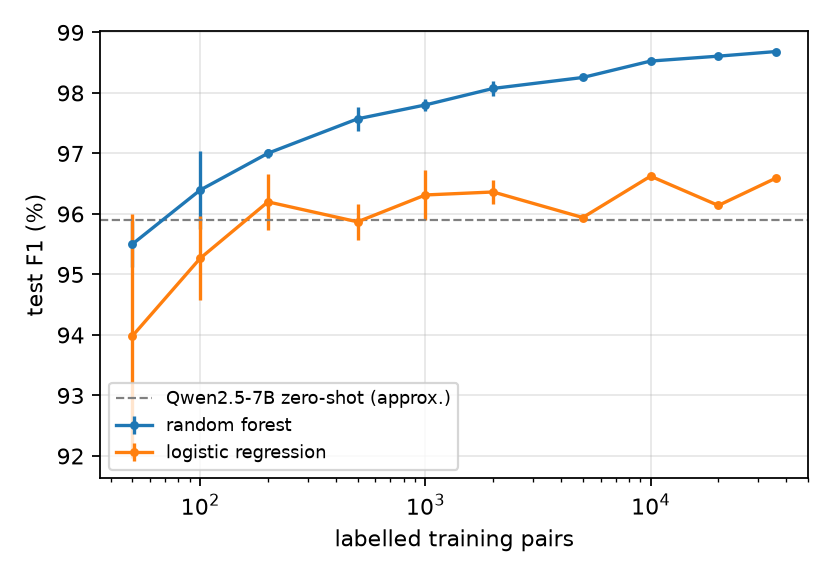

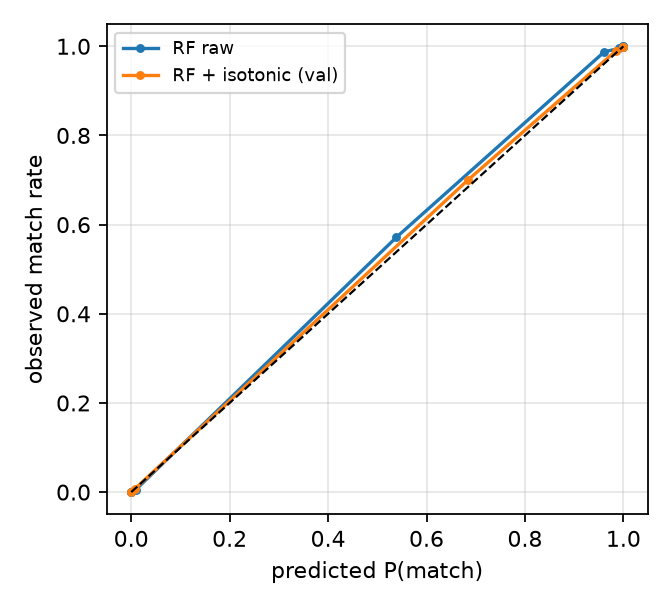

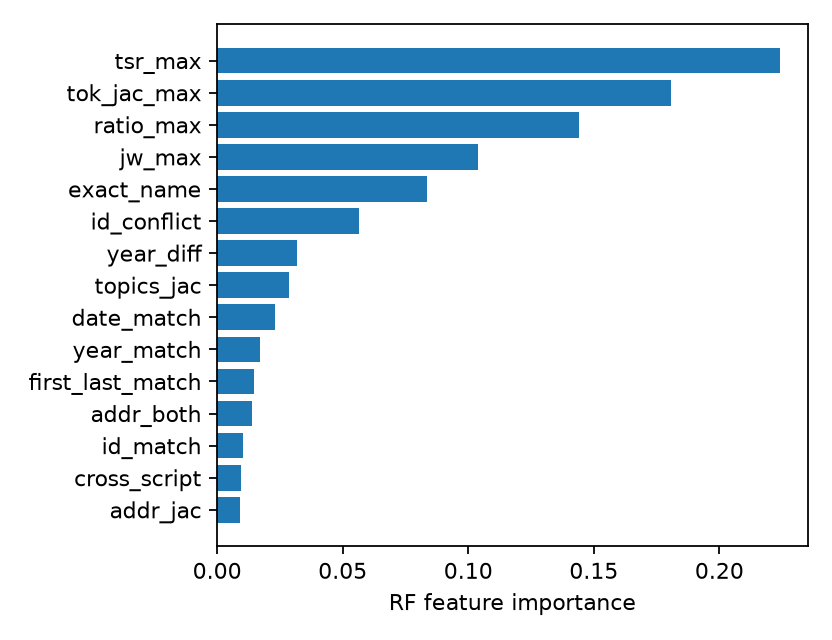

In [6]:
show("learning_curve.png",620);show("calibration.png",480);show("importance.png",620)

## 4. The LLM expert

Qwen2.5-7B-Instruct (bf16), Qwen2.5-14B-Instruct-AWQ (4-bit) and a 4-shot 7B variant, served with vLLM, temperature 0,
one-word `yes`/`no` answer, P(yes) from the first-token logprobs. Scoring 30k pairs (18k test + 12k gate-training pairs) took
376 s (7B), 850 s (14B) and 403 s (4-shot) on an H100 MIG slice. Commands (not re-run here):

```bash
python er_lib.py llm --model Qwen/Qwen2.5-7B-Instruct --which main
python er_lib.py llm --model Qwen/Qwen2.5-14B-Instruct-AWQ --which main
python er_lib.py llm --model Qwen/Qwen2.5-7B-Instruct --which main --shots 4
```

**The code that runs here.** The LLM as a matcher in `er_lib.py`. `render` turns a record into labelled lines, `PROMPT` is the exact prompt, `llm` scores a list of pairs with vLLM at temperature 0 and reads P(yes) from the first-token log probabilities. This stage runs on the GPU (`python er_lib.py llm --model ... --which main`, 6 to 14 minutes per model) and the notebook loads its saved answers from `data/llm_*.jsonl`.

`src/er_lib.py`, lines 179 to 194 (render and the prompt):

```python
def render(e,maxn=6):
    p=e["props"]
    lines=[f"type: {e['schema']}",f"name: {e['caption']}"]
    al=[x for k in ["name","alias","weakAlias","previousName"] for x in p.get(k,[]) if x!=e["caption"]]
    seen=set();al2=[]
    for a in al:
        if a not in seen:
            seen.add(a);al2.append(a)
    if al2:
        lines.append("other names: "+"; ".join(al2[:maxn]))
    for k,lab in [("birthDate","birth date"),("incorporationDate","incorporation date"),("dissolutionDate","dissolution date"),("gender","gender"),("nationality","nationality"),("citizenship","citizenship"),("country","country"),("jurisdiction","jurisdiction"),("flag","flag"),("birthPlace","birth place"),("address","address"),("position","position"),("legalForm","legal form"),("idNumber","id number"),("passportNumber","passport"),("registrationNumber","registration no"),("taxNumber","tax no"),("innCode","INN"),("ogrnCode","OGRN"),("leiCode","LEI"),("vatCode","VAT"),("imoNumber","IMO"),("mmsi","MMSI"),("callSign","call sign"),("wikidataId","wikidata")]:
        if p.get(k):
            lines.append(f"{lab}: "+"; ".join(p[k][:4]))
    return "\n".join(lines)

PROMPT="You are an expert analyst doing entity resolution on sanctions and watchlist data. Decide whether the two records below refer to the same real-world entity (same person, company or vessel). Names may be transliterated differently, abbreviated or only partially listed, and the two sources may record different subsets of fields. Minor inconsistencies in dates or identifiers are often data-entry errors and do not by themselves rule out a match. Different people can share a name, so use dates, places and identifiers to disambiguate.\n\nRecord A:\n{a}\n\nRecord B:\n{b}\n\nAnswer with exactly one word: yes or no."
```

`src/er_lib.py`, lines 196 to 203 (the four-shot block):

```python
def fewshot_block(rows,sp,k):
    rng=random.Random(1);pool=sp["train"][-4000:]
    pos=[i for i in pool if rows[i]["label"]==1];neg=[i for i in pool if rows[i]["label"]==0]
    ex=rng.sample(pos,k//2)+rng.sample(neg,k-k//2);rng.shuffle(ex)
    parts=["Here are some solved examples:"]
    for j,i in enumerate(ex):
        parts.append(f"Example {j+1}\nRecord A:\n{render(rows[i]['left'])}\n\nRecord B:\n{render(rows[i]['right'])}\n\nAnswer: {'yes' if rows[i]['label']==1 else 'no'}")
    return "\n\n".join(parts)+"\n\nNow the real question.\n\n"
```

`src/er_lib.py`, lines 205 to 236 (scoring with vLLM):

```python
def llm(model,which,maxn=None,shots=0):
    from vllm import LLM,SamplingParams
    rows=load_rows();sp=json.load(open(f"{DATA}/split.json"))
    sel=sp["test"]+sp["train"][:12000] if which=="main" else sp[which]
    if maxn:
        sel=sel[:maxn]
    llm=LLM(model=model,gpu_memory_utilization=0.85,max_model_len=6144,seed=0)
    tok=llm.get_tokenizer()
    fs=fewshot_block(rows,sp,shots) if shots else ""
    prompts=[tok.apply_chat_template([{"role":"user","content":fs+PROMPT.format(a=render(rows[i]["left"]),b=render(rows[i]["right"]))}],tokenize=False,add_generation_prompt=True) for i in sel]
    s=SamplingParams(temperature=0,max_tokens=3,logprobs=10)
    t0=time.time();res=llm.generate(prompts,s);dt=time.time()-t0
    out=[]
    for i,r in zip(sel,res):
        o=r.outputs[0];txt=o.text.strip().lower()
        py=pn=0.0
        if o.logprobs:
            for tid,lp in o.logprobs[0].items():
                t=(lp.decoded_token or "").strip().lower()
                if t in("yes","y"):
                    py+=np.exp(lp.logprob)
                elif t in("no","n"):
                    pn+=np.exp(lp.logprob)
        pred=1 if txt.startswith("yes") else (0 if txt.startswith("no") else (1 if py>pn else 0))
        out.append({"pid":int(rows[i]["pid"]),"idx":int(i),"pred":pred,"p_yes":float(py/(py+pn)) if (py+pn)>0 else float(pred),"raw":o.text,"ntok_in":len(r.prompt_token_ids)})
    tag=model.split("/")[-1]+(f"_{shots}shot" if shots else "")
    with open(f"{DATA}/llm_{tag}_{which}.jsonl","w") as f:
        for x in out:
            f.write(json.dumps(x)+"\n")
    y=np.array([rows[x["idx"]]["label"] for x in out]);p=np.array([x["pred"] for x in out])
    from sklearn.metrics import f1_score,accuracy_score
    print(f"[llm] {model} {which} n={len(out)} acc={accuracy_score(y,p):.4f} f1={f1_score(y,p):.4f} time={dt:.1f}s avg_in_tok={np.mean([x['ntok_in'] for x in out]):.0f}",flush=True)
```

In [7]:
print(E.PROMPT.format(a="<record A>",b="<record B>"))
from sklearn.metrics import f1_score,accuracy_score
y=F["y"];te=np.array(sp["test"])
for tag in ["Qwen2.5-7B-Instruct","Qwen2.5-14B-Instruct-AWQ","Qwen2.5-7B-Instruct_4shot"]:
    d={}
    for line in open(f"{DATA}/llm_{tag}_main.jsonl"):
        x=json.loads(line);d[x["idx"]]=x
    pred=np.array([d[i]["pred"] for i in te]);ntok=np.mean([d[i]["ntok_in"] for i in te])
    print(f"{tag:28s} test F1={f1_score(y[te],pred)*100:.2f} acc={accuracy_score(y[te],pred)*100:.2f} avg prompt tokens={ntok:.0f}")

You are an expert analyst doing entity resolution on sanctions and watchlist data. Decide whether the two records below refer to the same real-world entity (same person, company or vessel). Names may be transliterated differently, abbreviated or only partially listed, and the two sources may record different subsets of fields. Minor inconsistencies in dates or identifiers are often data-entry errors and do not by themselves rule out a match. Different people can share a name, so use dates, places and identifiers to disambiguate.

Record A:
<record A>

Record B:
<record B>

Answer with exactly one word: yes or no.
Qwen2.5-7B-Instruct          test F1=95.83 acc=94.67 avg prompt tokens=417


Qwen2.5-14B-Instruct-AWQ     test F1=96.58 acc=95.60 avg prompt tokens=417


Qwen2.5-7B-Instruct_4shot    test F1=94.45 acc=93.02 avg prompt tokens=1973


## 5. Deferral: when to hand a pair to an expert (complementarity, gates, deferral curves)

Reject option (Chow 1970): defer when $\min(p,1-p)>\lambda$; in budget form, rank test pairs by confidence and defer the top
fraction. Gates compared: confidence, learned error gate $\hat P(\text{matcher wrong}\mid x,p)$, learned gain gate
$\hat P(\text{expert right}\wedge\text{matcher wrong}\mid x,p)$ (learning to defer), random and oracle. Two experts: human
(assumed correct) and the LLM. Gates are trained on 12k training pairs with LLM answers, disjoint from calibration data and test.

**The code that runs here.** Gates and deferral curves in `er_gate.py`. The learned gates see the 29 features plus p, min(p,1-p) and the raw score, and are trained on 12k training pairs to predict the matcher's errors (`err`) or the pairs the LLM can fix (`gain`). `curve` is the deferral mechanic: rank by a score, replace the matcher's answer on the top fraction by the expert's answer, recompute F1.

`src/er_gate.py`, lines 19 to 36 (inputs, gate features, the two targets):

```python
P=np.load(f"{DATA}/matcher_probs.npz");pm=P[MODEL+"_cal"];praw=P[MODEL]
mres=json.load(open(f"{DATA}/matcher_results.json"));thr=0.5
llm={}
for line in open(f"{DATA}/llm_{LLMTAG}_main.jsonl"):
    r=json.loads(line);llm[r["idx"]]=r
G=np.array([i for i in tr[:12000] if i in llm]);T=np.array([i for i in te if i in llm])
print("gate-train",len(G),"test",len(T),flush=True)

def preds(idx):
    return (pm[idx]>=thr).astype(int),np.array([llm[i]["pred"] for i in idx]),np.array([llm[i]["p_yes"] for i in idx]),y[idx]

def gate_feats(idx):
    p=pm[idx];u=np.minimum(p,1-p)
    return np.column_stack([X[idx],p,u,praw[idx]])

ym_G,yl_G,pl_G,yt_G=preds(G);ym_T,yl_T,pl_T,yt_T=preds(T)
mw_G=(ym_G!=yt_G).astype(int);gain_G=((yl_G==yt_G)&(ym_G!=yt_G)).astype(int)
mw_T=(ym_T!=yt_T).astype(int);gain_T=((yl_T==yt_T)&(ym_T!=yt_T)).astype(int)
```

`src/er_gate.py`, lines 41 to 54 (the learned gates and the confidence gate):

```python
gates={}
XG=gate_feats(G);XT=gate_feats(T)
for tgt_name,tgt in [("err",mw_G),("gain",gain_G)]:
    if tgt.sum()<5:
        continue
    hgb=HistGradientBoostingClassifier(max_iter=300,learning_rate=0.05,class_weight="balanced",random_state=0).fit(XG,tgt)
    lr=make_pipeline(StandardScaler(),LogisticRegression(C=0.5,class_weight="balanced",max_iter=5000)).fit(XG,tgt)
    gates[f"hgb_{tgt_name}"]=hgb.predict_proba(XT)[:,1]
    gates[f"lr_{tgt_name}"]=lr.predict_proba(XT)[:,1]
    ref=mw_T if tgt_name=="err" else gain_T
    for k in [f"hgb_{tgt_name}",f"lr_{tgt_name}"]:
        print(f"gate {k}: AUC vs {tgt_name} on test = {roc_auc_score(ref,gates[k]):.4f}",flush=True)
conf=np.minimum(pm[T],1-pm[T])
print(f"gate conf: AUC vs err={roc_auc_score(mw_T,conf):.4f} vs gain={roc_auc_score(gain_T,conf):.4f}" if gain_T.sum()>0 else "",flush=True)
```

`src/er_gate.py`, lines 56 to 76 (deferral curves for the confidence, random, oracle and learned gates, human and LLM experts):

```python
fracs=[0,0.01,0.02,0.03,0.05,0.075,0.1,0.15,0.2,0.3,0.4,0.5,0.75,1.0]
def curve(score,expert):
    out=[]
    order=np.argsort(-score)
    for f in fracs:
        k=int(round(f*len(T)));d=np.zeros(len(T),bool);d[order[:k]]=True
        yhat=ym_T.copy()
        yhat[d]=yl_T[d] if expert=="llm" else yt_T[d]
        out.append({"frac":f,"f1":float(f1_score(yt_T,yhat)),"acc":float(accuracy_score(yt_T,yhat)),"errors":int((yhat!=yt_T).sum())})
    return out
def random_curve(expert,reps=20):
    rng=np.random.default_rng(0);acc=[]
    for _ in range(reps):
        acc.append(curve(rng.random(len(T)),expert))
    return [{"frac":fracs[i],"f1":float(np.mean([c[i]["f1"] for c in acc])),"acc":float(np.mean([c[i]["acc"] for c in acc])),"errors":float(np.mean([c[i]["errors"] for c in acc]))} for i in range(len(fracs))]
res={"matcher":MODEL,"llm":LLMTAG,"n_test":len(T),"matcher_f1":float(f1_score(yt_T,ym_T)),"llm_f1":float(f1_score(yt_T,yl_T)),"complementarity":{"both_right":float(both_r),"matcher_only":float(m_only),"llm_only":float(l_only),"both_wrong":float(both_w)},"curves":{}}
for expert in ["llm","human"]:
    c={"confidence":curve(conf,expert),"random":random_curve(expert),"oracle":curve((gain_T if expert=="llm" else mw_T).astype(float)+conf*1e-3,expert)}
    for k,v in gates.items():
        c[k]=curve(v,expert)
    res["curves"][expert]=c
```

In [8]:
%run $SRC/er_gate.py rf Qwen2.5-7B-Instruct

gate-train 12000 test 18000


matcher F1 test=0.9872 acc=0.9831 | LLM F1 test=0.9583 acc=0.9467


complementarity: both right=0.9364 matcher-only right=0.0467 LLM-only right=0.0103 both wrong=0.0066


gate hgb_err: AUC vs err on test = 0.9316


gate lr_err: AUC vs err on test = 0.9238


gate hgb_gain: AUC vs gain on test = 0.8825


gate lr_gain: AUC vs gain on test = 0.9256


gate conf: AUC vs err=0.9452 vs gain=0.9555


== expert=llm
frac     confidence       random       oracle      hgb_err       lr_err     hgb_gain      lr_gain
0.000         98.72        98.72        98.72        98.72        98.72        98.72        98.72
0.010         98.76        98.69        99.48        98.78        98.75        98.76        98.72
0.020         98.78        98.67        99.33        98.88        98.78        98.86        98.81
0.030         98.80        98.64        99.22        98.94        98.87        98.95        98.87
0.050         98.85        98.58        99.05        98.90        98.85        98.79        98.84
0.075         98.73        98.51        98.87        98.81        98.80        98.68        98.78
0.100         98.63        98.43        98.72        98.68        98.76        98.34        98.73
0.150         98.28        98.29        98.32        98.31        98.61        97.97        98.44
0.200         97.81        98.15        97.88        97.93        98.49        97.52        98.13
0.300 

profile of 10% deferred (confidence gate):
  cross_script       deferred=0.119 kept=0.065
  date_missing       deferred=0.839 kept=0.398
  kind_org           deferred=0.552 kept=0.333
  exact_name         deferred=0.518 kept=0.570
  id_both            deferred=0.312 kept=0.435
  geo_conflict       deferred=0.044 kept=0.111
  date_both          deferred=0.161 kept=0.602
  jw_max             deferred=0.920 kept=0.897
  tsr_max            deferred=0.939 kept=0.875
  pos_rate           deferred=0.701 kept=0.650
  matcher_err_rate   deferred=0.144 kept=0.003
  llm_err_rate       deferred=0.154 kept=0.042
GATE_DONE


In [9]:
%run $SRC/er_gate.py rf Qwen2.5-14B-Instruct-AWQ

gate-train 12000 test 18000


matcher F1 test=0.9872 acc=0.9831 | LLM F1 test=0.9658 acc=0.9560


complementarity: both right=0.9455 matcher-only right=0.0376 LLM-only right=0.0105 both wrong=0.0064


gate hgb_err: AUC vs err on test = 0.9316


gate lr_err: AUC vs err on test = 0.9238


gate hgb_gain: AUC vs gain on test = 0.8699


gate lr_gain: AUC vs gain on test = 0.9193


gate conf: AUC vs err=0.9452 vs gain=0.9586


== expert=llm
frac     confidence       random       oracle      hgb_err       lr_err     hgb_gain      lr_gain
0.000         98.72        98.72        98.72        98.72        98.72        98.72        98.72
0.010         98.77        98.70        99.48        98.78        98.76        98.83        98.75
0.020         98.82        98.68        99.37        98.89        98.79        98.94        98.81
0.030         98.87        98.66        99.31        98.97        98.92        98.98        98.93
0.050         98.94        98.62        99.17        98.95        98.93        98.91        98.92
0.075         98.87        98.57        98.97        98.89        98.92        98.80        98.86
0.100         98.83        98.51        98.90        98.76        98.91        98.63        98.85
0.150         98.52        98.41        98.56        98.49        98.82        98.51        98.80
0.200         98.18        98.30        98.25        98.16        98.76        98.03        98.67
0.300 

profile of 10% deferred (confidence gate):
  cross_script       deferred=0.119 kept=0.065
  date_missing       deferred=0.839 kept=0.398
  kind_org           deferred=0.552 kept=0.333
  exact_name         deferred=0.518 kept=0.570
  id_both            deferred=0.312 kept=0.435
  geo_conflict       deferred=0.044 kept=0.111
  date_both          deferred=0.161 kept=0.602
  jw_max             deferred=0.920 kept=0.897
  tsr_max            deferred=0.939 kept=0.875
  pos_rate           deferred=0.701 kept=0.650
  matcher_err_rate   deferred=0.144 kept=0.003
  llm_err_rate       deferred=0.129 kept=0.035
GATE_DONE


In [10]:
%run $SRC/er_gate.py rf Qwen2.5-7B-Instruct_4shot

gate-train 12000 test 18000


matcher F1 test=0.9872 acc=0.9831 | LLM F1 test=0.9445 acc=0.9302


complementarity: both right=0.9199 matcher-only right=0.0632 LLM-only right=0.0103 both wrong=0.0066


gate hgb_err: AUC vs err on test = 0.9316


gate lr_err: AUC vs err on test = 0.9238


gate hgb_gain: AUC vs gain on test = 0.9136


gate lr_gain: AUC vs gain on test = 0.9278


gate conf: AUC vs err=0.9452 vs gain=0.9580


== expert=llm
frac     confidence       random       oracle      hgb_err       lr_err     hgb_gain      lr_gain
0.000         98.72        98.72        98.72        98.72        98.72        98.72        98.72
0.010         98.77        98.68        99.48        98.78        98.76        98.81        98.72
0.020         98.72        98.64        99.27        98.84        98.75        98.82        98.73
0.030         98.68        98.61        99.11        98.83        98.77        98.78        98.79
0.050         98.69        98.52        98.89        98.72        98.70        98.59        98.71
0.075         98.51        98.42        98.60        98.55        98.56        98.20        98.57
0.100         98.30        98.31        98.37        98.39        98.48        98.01        98.50
0.150         97.72        98.10        97.76        97.77        98.07        97.82        98.04
0.200         97.10        97.90        97.19        97.22        97.88        97.64        97.70
0.300 

profile of 10% deferred (confidence gate):
  cross_script       deferred=0.119 kept=0.065
  date_missing       deferred=0.839 kept=0.398
  kind_org           deferred=0.552 kept=0.333
  exact_name         deferred=0.518 kept=0.570
  id_both            deferred=0.312 kept=0.435
  geo_conflict       deferred=0.044 kept=0.111
  date_both          deferred=0.161 kept=0.602
  jw_max             deferred=0.920 kept=0.897
  tsr_max            deferred=0.939 kept=0.875
  pos_rate           deferred=0.701 kept=0.650
  matcher_err_rate   deferred=0.144 kept=0.003
  llm_err_rate       deferred=0.197 kept=0.056
GATE_DONE


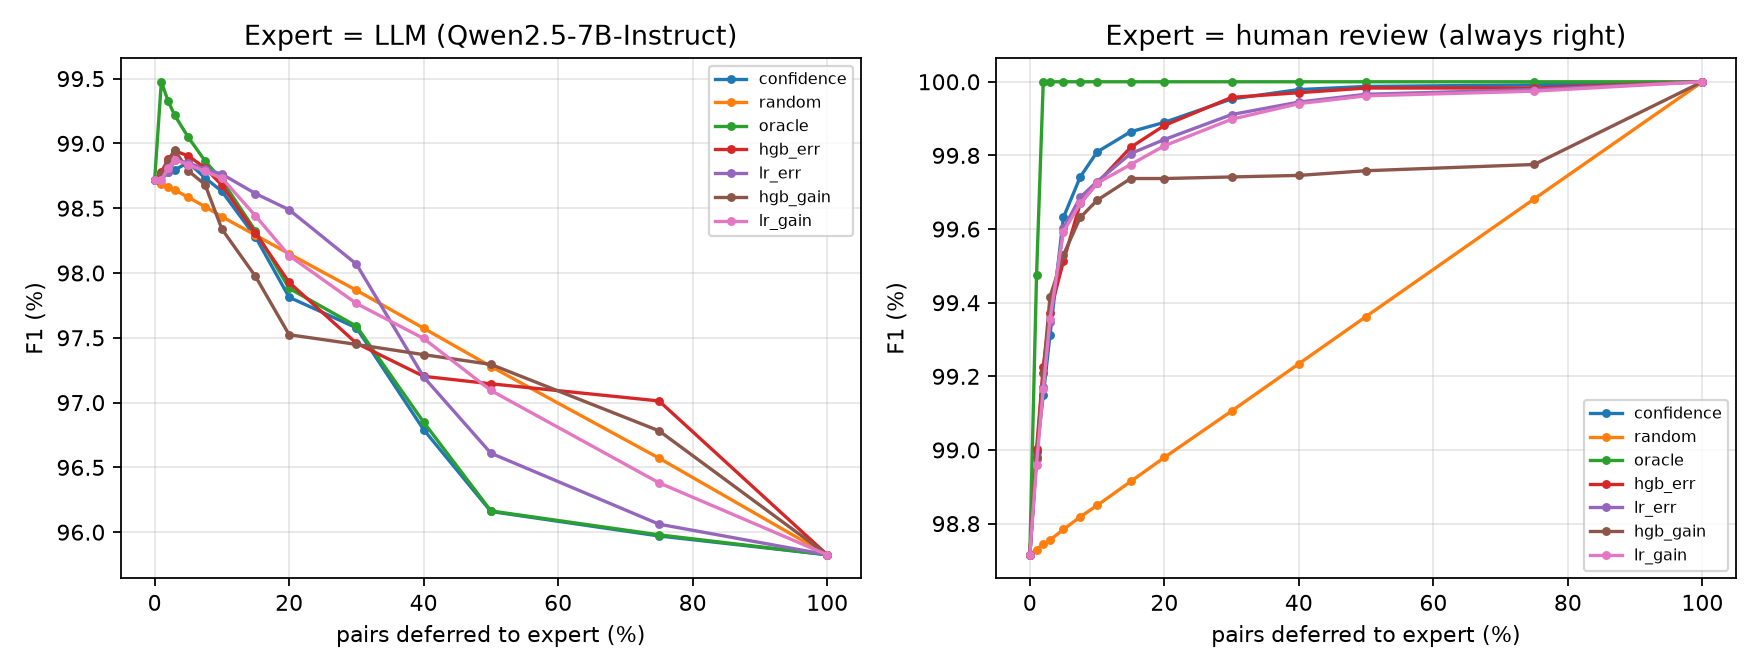

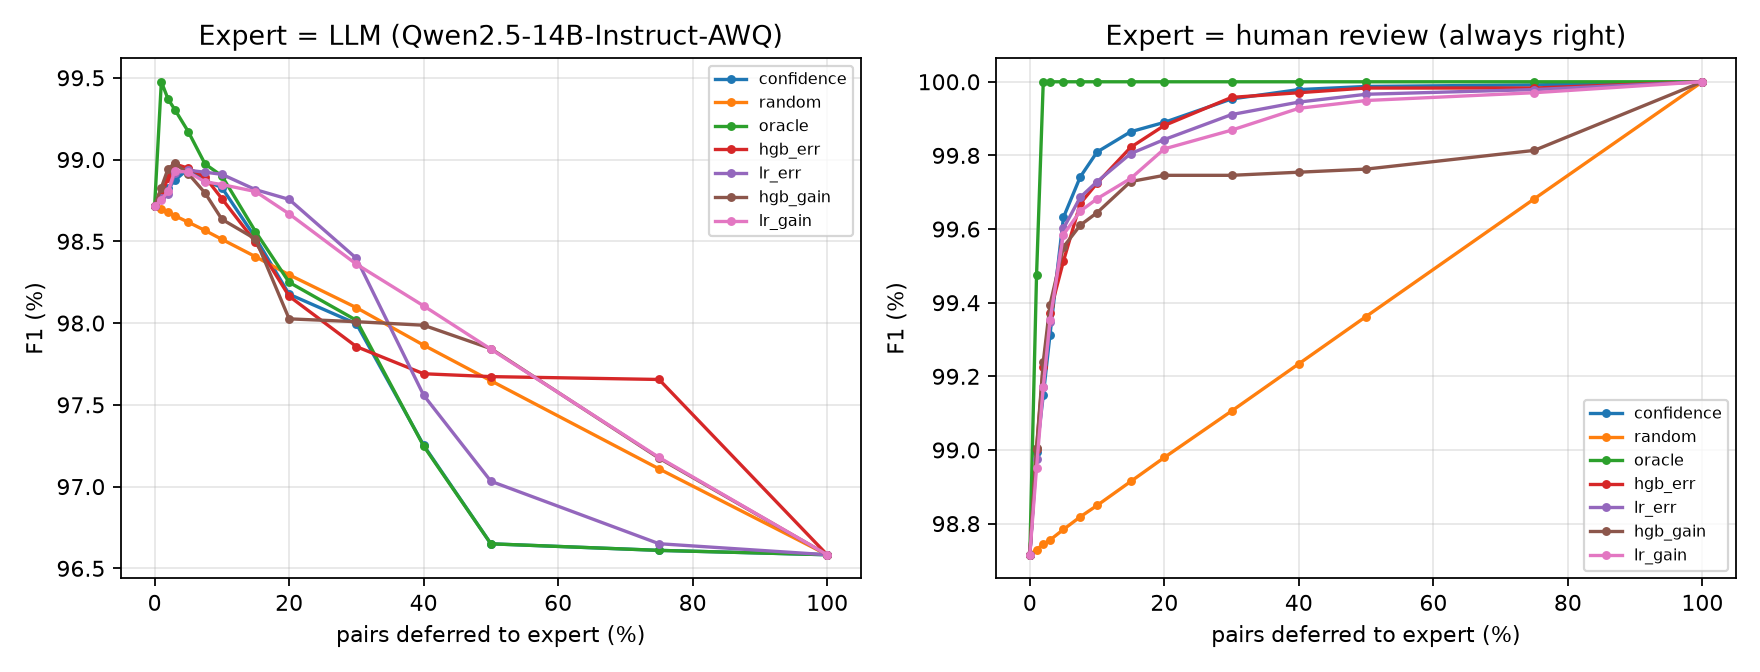

In [11]:
show("deferral_curves_Qwen2.5-7B-Instruct.png",900);show("deferral_curves_Qwen2.5-14B-Instruct-AWQ.png",900)

## 6. The hard core: pairs that every system gets wrong

**The code that runs here.** The hard core in `er_core.py`: test pairs that the matcher and all three LLM runs get wrong.

`src/er_core.py`, lines 8 to 31:

```python
tags=["Qwen2.5-7B-Instruct","Qwen2.5-14B-Instruct-AWQ","Qwen2.5-7B-Instruct_4shot"]
L={}
for t in tags:
    d={}
    for line in open(f"{DATA}/llm_{t}_main.jsonl"):
        r=json.loads(line);d[r["idx"]]=r["pred"]
    L[t]=np.array([d[i] for i in te])
yt=y[te];mw=pm[te]!=yt
both={t:set(te[mw&(L[t]!=yt)]) for t in tags}
llmonly={t:set(te[(~mw)&(L[t]!=yt)]) for t in tags}
out={"matcher_wrong":int(mw.sum())}
print("matcher wrong on test:",mw.sum())
for t in tags:
    print(f"{t:28s} both-wrong={len(both[t])} llm-wrong-total={(L[t]!=yt).sum()}")
    out[t]={"both_wrong":len(both[t]),"llm_wrong":int((L[t]!=yt).sum())}
for a,b in itertools.combinations(tags,2):
    j=len(both[a]&both[b])/len(both[a]|both[b])
    print(f"both-wrong overlap {a.split('-')[1]} vs {b.split('-')[1].replace('Instruct_','')}: inter={len(both[a]&both[b])} jaccard={j:.3f}")
    out[f"jaccard_{a}_{b}"]=j
core=both[tags[0]]&both[tags[1]]&both[tags[2]]
print("pairs wrong for matcher AND all three LLM configs:",len(core))
out["core_all"]=len(core)
# characterise the core: label distribution + feature means vs rest of test
ci=np.array(sorted(core));rest=np.array([i for i in te if i not in core])
```

In [12]:
%run $SRC/er_core.py
print(open(f"{DATA}/core_examples.txt").read()[:3500])

matcher wrong on test: 304
Qwen2.5-7B-Instruct          both-wrong=118 llm-wrong-total=959
Qwen2.5-14B-Instruct-AWQ     both-wrong=115 llm-wrong-total=792
Qwen2.5-7B-Instruct_4shot    both-wrong=119 llm-wrong-total=1257
both-wrong overlap 7B vs 14B: inter=101 jaccard=0.765
both-wrong overlap 7B vs 7B: inter=103 jaccard=0.769
both-wrong overlap 14B vs 7B: inter=91 jaccard=0.636
pairs wrong for matcher AND all three LLM configs: 89
core label mean (1=analyst said match): 0.21348314606741572 | matcher said match on core: 0.7865168539325843
  exact_name     core=0.629 rest=0.565
  jw_max         core=0.927 rest=0.899
  date_both      core=0.146 rest=0.560
  date_match     core=0.022 rest=0.310
  year_match     core=0.034 rest=0.386
  id_both        core=0.180 rest=0.424
  id_match       core=0.056 rest=0.195
  id_conflict    core=0.124 rest=0.228
  geo_conflict   core=0.011 rest=0.105
  cross_script   core=0.146 rest=0.070
  kind_org       core=0.528 rest=0.354
  date_missing   core=0.854 

===== pid=49235 analyst_label=1 matcher_p=0.003 llm7=0
type: Organization
name: Donetsk Republic
other names: Mouvement public “République de Donetsk”; Movimiento público “República de Donetsk”; Rahvaliikumine „Donetski Vabariik“; Javno gibanje ‚Republika Doneck‘; Movimento pubblico “Repubblica di Donetsk”; Javni pokret „Republika Donjeck”
country: ua
address: Universitetskaya 19, Donetsk, Ukraine; Donetsk, Universitetskaya 19; Universitetskaya 19, Donetsk; Донецк, ул. Университетская, дом 19
legal form: Public Government Body
--- vs ---
type: Organization
name: So-called 'Lugansk People's Republic'
other names: Self-proclaimed “Luhansk People's Republic”; 'Луганская народная республика' (ЛНР); Tzv. Luhanská ľudová republika; So-called “Luhansk People’s Republic”; Sogenannte „Volksrepublik Luhansk“; 'Luganskaya narodnaya respublika' (LNR)
country: ua
address: Luhansk Region; Square Geroev Velikoy Otechestvennoy Voyny 3, Luhansk, Ukraine
legal form: Unrecognized Government Entity; Enter

## 7. Robustness: feature ablation, cross-type generalisation, leakage checks, difficulty strata

**The code that runs here.** Feature-group ablation in `er_ablate.py`: a forest and a logistic regression per feature group. `all` against `no_counts` is the count-feature leakage check.

`src/er_ablate.py`, lines 13 to 26:

```python
NAME=["jw_max","tsr_max","tok_jac_max","ratio_max","exact_name","first_last_match"]
COUNTS=["n_names_l","n_names_r","nprops_l","nprops_r","nprops_min"]
ATTR=["kind_person","kind_org","kind_mismatch","date_both","date_match","year_match","year_diff","date_missing","geo_both","geo_jac","geo_any","geo_conflict","gender_both","gender_mismatch","id_both","id_match","id_conflict","addr_both","addr_jac","bplace_match","pos_jac","cross_script"]
TOPIC=["topics_jac"]
groups={"all":names,"no_counts":NAME+ATTR+TOPIC,"no_counts_no_topics":NAME+ATTR,"names_only":NAME,"names+dates":NAME+["date_both","date_match","year_match","year_diff","date_missing"],"attrs_only(no names)":ATTR+TOPIC+COUNTS,"counts_only":COUNTS,"no_exact_name":[c for c in names if c!="exact_name"]}
out={}
for g,cols in groups.items():
    c=idx(cols)
    rf=RandomForestClassifier(n_estimators=300,min_samples_leaf=2,class_weight="balanced_subsample",n_jobs=-1,random_state=0).fit(X[tr][:,c],y[tr])
    p=rf.predict_proba(X[te][:,c])[:,1]
    lr=make_pipeline(StandardScaler(),LogisticRegression(C=1.0,class_weight="balanced",max_iter=5000)).fit(X[tr][:,c],y[tr])
    pl=lr.predict_proba(X[te][:,c])[:,1]
    out[g]={"rf_f1":float(f1_score(y[te],p>=0.5)),"rf_auc":float(roc_auc_score(y[te],p)),"lr_f1":float(f1_score(y[te],pl>=0.5)),"lr_auc":float(roc_auc_score(y[te],pl)),"n_feats":len(c)}
    print(f"{g:22s} nf={len(c):2d} RF F1={out[g]['rf_f1']:.4f} AUC={out[g]['rf_auc']:.4f} | LR F1={out[g]['lr_f1']:.4f} AUC={out[g]['lr_auc']:.4f}",flush=True)
```

In [13]:
%run $SRC/er_ablate.py

all                    nf=34 RF F1=0.9899 AUC=0.9983 | LR F1=0.9716 AUC=0.9919


no_counts              nf=29 RF F1=0.9869 AUC=0.9974 | LR F1=0.9659 AUC=0.9891


no_counts_no_topics    nf=28 RF F1=0.9855 AUC=0.9965 | LR F1=0.9652 AUC=0.9887


names_only             nf= 6 RF F1=0.9698 AUC=0.9777 | LR F1=0.9433 AUC=0.9559


names+dates            nf=11 RF F1=0.9730 AUC=0.9867 | LR F1=0.9497 AUC=0.9733


attrs_only(no names)   nf=28 RF F1=0.9742 AUC=0.9936 | LR F1=0.9389 AUC=0.9726


counts_only            nf= 5 RF F1=0.8568 AUC=0.8918 | LR F1=0.7778 AUC=0.7934


no_exact_name          nf=33 RF F1=0.9900 AUC=0.9983 | LR F1=0.9713 AUC=0.9915


exact_name       pos=0.842 neg=0.040
cross_script     pos=0.100 neg=0.016
date_both        pos=0.570 neg=0.543
date_match       pos=0.462 neg=0.013
year_match       pos=0.552 neg=0.071
date_missing     pos=0.430 neg=0.457
id_both          pos=0.329 neg=0.593
id_match         pos=0.283 neg=0.018
id_conflict      pos=0.047 neg=0.576
geo_conflict     pos=0.008 neg=0.280
gender_mismatch  pos=0.000 neg=0.011
kind_mismatch    pos=0.016 neg=0.003
geo_any          pos=0.793 neg=0.665
jw_max           pos mean=0.967 med=1.000 | neg mean=0.772 med=0.756
tsr_max          pos mean=0.977 med=1.000 | neg mean=0.697 med=0.667
n_names_l        pos mean=1.008 med=0.693 | neg mean=1.628 med=1.609
n_names_r        pos mean=1.361 med=1.099 | neg mean=1.771 med=1.792
nprops_l         pos mean=2.000 med=2.079 | neg mean=2.303 med=2.398
nprops_r         pos mean=2.262 med=2.303 | neg mean=2.389 med=2.485
ABL_DONE


In [14]:
%run $SRC/er_xtype.py

train person       (22092) -> test org          ( 6380): F1=0.9003 AUC=0.9599 | model trained on everything: F1=0.9706


train org          (12881) -> test person       (11081): F1=0.9781 AUC=0.9660 | model trained on everything: F1=0.9927


train same_script  (33460) -> test cross_script ( 1267): F1=0.9708 AUC=0.9717 | model trained on everything: F1=0.9828


train person       (22092) -> test person       (11081): F1=0.9924 AUC=0.9984 | model trained on everything: F1=0.9927


train org          (12881) -> test org          ( 6380): F1=0.9713 AUC=0.9937 | model trained on everything: F1=0.9706


train cross_script ( 2540) -> test cross_script ( 1267): F1=0.9748 AUC=0.9808 | model trained on everything: F1=0.9828


XTYPE_DONE


In [15]:
%run $SRC/er_leakcheck.py

test pairs by #entities already seen in some TRAIN pair:
  neither seen  n= 9578 (53.2%) pos=0.92 RF F1=0.9909 err=0.0167 | 7B LLM err=0.0772 | 14B LLM err=0.0659
  one seen      n= 4876 (27.1%) pos=0.61 RF F1=0.9823 err=0.0217 | 7B LLM err=0.0416 | 14B LLM err=0.0306
  both seen     n= 3546 (19.7%) pos=0.01 RF F1=0.6346 err=0.0107 | 7B LLM err=0.0048 | 14B LLM err=0.0034


test pairs whose exact record contents also appear as a TRAIN pair: 40 (0.22%)
   on those: pos=0.88 RF err=0.0750
   on the rest: RF F1=0.9872 err=0.0168


test pairs where both records are byte-identical: 160 (pos rate 0.95625)
distinct entity ids in sample: 86380 over 60000 pairs; max degree 22; mean degree 1.39
  label=0: frac both-seen=0.565 one-seen=0.306 neither=0.129
  label=1: frac both-seen=0.003 one-seen=0.253 neither=0.744
LEAK_DONE


In [16]:
%run $SRC/er_strata.py

all test                           n=18000 pos=0.65 RF F1=0.9872 err=0.0169 | 7B F1=0.9583 err=0.0533 | 14B-AWQ F1=0.9658 err=0.0440 | 7B_4shot F1=0.9445 err=0.0698


excluding byte-identical pairs     n=17840 pos=0.65 RF F1=0.9873 err=0.0166 | 7B F1=0.9580 err=0.0534 | 14B-AWQ F1=0.9657 err=0.0440 | 7B_4shot F1=0.9440 err=0.0701


exact normalised name shared       n=10172 pos=0.98 RF F1=0.9920 err=0.0156 | 7B F1=0.9717 err=0.0543 | 14B-AWQ F1=0.9790 err=0.0406 | 7B_4shot F1=0.9620 err=0.0723


NO exact name shared (hard)        n= 7828 pos=0.24 RF F1=0.9611 err=0.0185 | 7B F1=0.8827 err=0.0520 | 14B-AWQ F1=0.8925 err=0.0484 | 7B_4shot F1=0.8424 err=0.0667


no exact name, jw>=0.9             n= 1625 pos=0.43 RF F1=0.9570 err=0.0369 | 7B F1=0.9473 err=0.0443 | 14B-AWQ F1=0.9628 err=0.0320 | 7B_4shot F1=0.9142 err=0.0695


no exact name, jw<0.9              n= 6203 pos=0.19 RF F1=0.9636 err=0.0137 | 7B F1=0.8409 err=0.0540 | 14B-AWQ F1=0.8464 err=0.0527 | 7B_4shot F1=0.7950 err=0.0659


byte-identical pairs               n=  160 pos=0.96 RF F1=0.9776 err=0.0437 | 7B F1=0.9776 err=0.0437 | 14B-AWQ F1=0.9776 err=0.0437 | 7B_4shot F1=0.9776 err=0.0437


hard subset, defer 5% to human: F1 0.9611 -> 0.9863 (kept-part F1 0.9845)


hard subset, defer 10% to human: F1 0.9611 -> 0.9952 (kept-part F1 0.9937)


hard subset, defer 20% to human: F1 0.9611 -> 0.9976 (kept-part F1 0.9951)


STRATA_DONE


## 8. Not a lucky sample: the forest on all 375,842 other analyst-judged pairs

The matcher trained on the 36k training split is applied to every other entity pair in the raw file (none of them seen in
training, validation or test). Needs the raw file at `ER_RAW`.

**The code that runs here.** The sampling-luck check in `er_fullpop.py`: the raw file is streamed again with the same filter, every pair not in the 60k sample is featurised, and the forest trained on the 36k training split (with the isotonic map from the 6k validation split) scores all of them. The confidence interval is a 200-draw bootstrap.

`src/er_fullpop.py`, lines 15 to 46 (stream, featurise, score):

```python
sampled=set()
for r in rows:
    a,b=r["left"]["id"],r["right"]["id"];sampled.add((a,b) if a<b else (b,a))
print("sampled pairs",len(sampled),flush=True)
# stream the raw file with exactly the same filter/dedup as er_lib.sample, keep everything not sampled
t0=time.time();seen=set();X=[];y=[];schema=[];cnt=collections.Counter()
with gzip.open(E.RAW,"rt") as f:
    for line in f:
        r=json.loads(line);j=r.get("judgement")
        if j not in("positive","negative"):
            continue
        a,b=r["left"]["id"],r["right"]["id"]
        if a==b or r["left"].get("schema") not in E.SCHEMAS or r["right"].get("schema") not in E.SCHEMAS:
            continue
        key=(a,b) if a<b else (b,a)
        if key in seen:
            continue
        seen.add(key)
        if key in sampled:
            cnt["in_sample"]+=1;continue
        l,rr=E.strip(r["left"]),E.strip(r["right"])
        X.append(E.pair_feats(l,rr));y.append(int(j=="positive"));schema.append((l["schema"],rr["schema"]))
        cnt[j]+=1
        if len(y)%50000==0:
            print(len(y),"pairs featurised",round(time.time()-t0),"s",flush=True)
X=np.array(X,dtype=np.float32);y=np.array(y)
print("held-out population:",dict(cnt),"pos rate",y.mean().round(4),"time",round(time.time()-t0),"s",flush=True)
names=list(E.FEATS);keep=[i for i,n in enumerate(names) if n not in DROP];X=X[:,keep];names=[names[i] for i in keep]
F=np.load(f"{DATA}/feats.npz",allow_pickle=True);Xs=F["X"][:,keep];ys=F["y"];tr=np.array(sp["train"]);va=np.array(sp["val"]);te=np.array(sp["test"])
rf=RandomForestClassifier(n_estimators=400,min_samples_leaf=2,class_weight="balanced_subsample",n_jobs=-1,random_state=0).fit(Xs[tr],ys[tr])
iso=IsotonicRegression(out_of_bounds="clip").fit(rf.predict_proba(Xs[va])[:,1],ys[va])
p=iso.predict(rf.predict_proba(X)[:,1]);pt=iso.predict(rf.predict_proba(Xs[te])[:,1])
```

`src/er_fullpop.py`, lines 53 to 57 (bootstrap confidence interval):

```python
# bootstrap CI on held-out F1
rng=np.random.default_rng(0);bs=[]
for _ in range(200):
    idx=rng.integers(0,len(y),len(y));bs.append(f1_score(y[idx],p[idx]>=0.5))
out["rf_heldout_f1_ci95"]=[float(np.percentile(bs,2.5)),float(np.percentile(bs,97.5))];print("held-out F1 95% bootstrap CI",np.round(out["rf_heldout_f1_ci95"],4),flush=True)
```

In [17]:
%run $SRC/er_fullpop.py

sampled pairs 60000


50000 pairs featurised 10 s


100000 pairs featurised 24 s


150000 pairs featurised 34 s


200000 pairs featurised 47 s


250000 pairs featurised 64 s


... (14 outputs left out)

held-out human deferral 2%: F1 0.9847 -> 0.9907


held-out human deferral 5%: F1 0.9847 -> 0.9956


held-out human deferral 10%: F1 0.9847 -> 0.9978


FULLPOP_DONE


## 9. Decision theory extras: an imperfect reviewer, asymmetric costs, combining instead of deferring

The human expert above is perfect by construction. Here the reviewed labels are flipped with probability eps (20 draws), the Bayes
reject region is recomputed for unequal costs of a missed match, a false match and a review (defer when c_d/c_FN < p < 1 - c_d/c_FP),
and the LLM is combined with the matcher (weighted average, logistic stacker, LLM probability as a 30th feature) instead of replacing it on deferred pairs.

**The code that runs here.** Decision-theory extras in `er_decision.py`. (B) combines the matcher and the LLM instead of deferring. (C) flips the reviewer's answer with probability eps on the deferred pairs. (D) applies the three-way Bayes rule with costs c_fp = 1, c_fn in {1, 3, 10}, c_d in {0.05, 0.1, 0.2, 0.5} and compares the total cost with the best single threshold without a reject option.

`src/er_decision.py`, lines 39 to 50 (combination):

```python
# (B) combination
comb={"matcher":base,"llm":f1(T,yl[T])}
comb["average"]=f1(T,((pm[T]+pl[T])/2>=0.5).astype(int))
ws=np.linspace(0,1,101);best=max(ws,key=lambda w:f1(G,((w*pm[G]+(1-w)*pl[G])>=0.5).astype(int)))
comb["weighted_w"]=float(best);comb["weighted"]=f1(T,((best*pm[T]+(1-best)*pl[T])>=0.5).astype(int))
st=LogisticRegression(C=1.0,max_iter=2000).fit(np.column_stack([logit(pm[G]),logit(pl[G])]),y[G])
comb["stacker_lr"]=f1(T,st.predict(np.column_stack([logit(pm[T]),logit(pl[T])])));comb["stacker_coef"]=[float(c) for c in st.coef_[0]]
rf_kw=dict(n_estimators=400,min_samples_leaf=2,class_weight="balanced_subsample",n_jobs=-1,random_state=0)
rfG=RandomForestClassifier(**rf_kw).fit(X[G],y[G]);comb["rf_12k_29feats"]=f1(T,rfG.predict(X[T]))
rfL=RandomForestClassifier(**rf_kw).fit(np.column_stack([X[G],pl[G]]),y[G]);comb["rf_12k_29feats+llm"]=f1(T,rfL.predict(np.column_stack([X[T],pl[T]])))
imp=rfL.feature_importances_;comb["llm_feature_importance"]=float(imp[-1]);comb["llm_feature_rank"]=int((imp>imp[-1]).sum()+1)
res["combination"]=comb
```

`src/er_decision.py`, lines 53 to 67 (noisy reviewer):

```python
# (C) noisy human
conf=np.minimum(pm[T],1-pm[T]);order=np.argsort(-conf);ym=(pm[T]>=0.5).astype(int);yt=y[T]
fracs=[0,0.01,0.02,0.05,0.1,0.2];epss=[0,0.02,0.05,0.1,0.2];rng=np.random.default_rng(0)
noisy={}
for eps in epss:
    row=[]
    for f in fracs:
        k=int(round(f*len(T)));d=order[:k];vals=[]
        for _ in range(20 if eps>0 else 1):
            yh=ym.copy();flip=rng.random(k)<eps;yh[d]=np.where(flip,1-yt[d],yt[d]);vals.append(f1_score(yt,yh))
        row.append({"frac":f,"f1":float(np.mean(vals))})
    noisy[str(eps)]=row
k5=int(0.05*len(T));d5=order[:k5];err_rate_deferred=float((ym[d5]!=yt[d5]).mean())
noisy["matcher_error_rate_on_deferred_5pct"]=err_rate_deferred
res["noisy_human"]=noisy
```

`src/er_decision.py`, lines 74 to 85 (asymmetric costs, the reject region is lo < p < hi):

```python
# (D) asymmetric costs with a reject option. Costs: false match c_fp=1, missed match c_fn, deferral c_d (human assumed right).
cost={};c_fp=1.0
for c_fn in [1,3,10]:
    for c_d in [0.05,0.1,0.2,0.5]:
        lo=c_d/c_fn;hi=1-c_d/c_fp           # defer when p*c_fn>c_d and (1-p)*c_fp>c_d
        p=pm[T];say_yes=(1-p)*c_fp<=np.minimum(p*c_fn,c_d);say_no=(p*c_fn<np.minimum((1-p)*c_fp,c_d));defer=~(say_yes|say_no)
        fp=int((say_yes&(yt==0)).sum());fn=int((say_no&(yt==1)).sum());nd=int(defer.sum())
        total=c_fp*fp+c_fn*fn+c_d*nd
        # best single threshold without reject (same costs)
        ths=np.linspace(0.01,0.99,99);costs=[c_fp*((p>=t)&(yt==0)).sum()+c_fn*((p<t)&(yt==1)).sum() for t in ths];j=int(np.argmin(costs))
        cost[f"cfn={c_fn},cd={c_d}"]={"region":[float(lo),float(hi)] if lo<hi else None,"defer_frac":nd/len(T),"fp":fp,"fn":fn,"cost_per_1000":total/len(T)*1000,"no_reject_best_thr":float(ths[j]),"no_reject_cost_per_1000":costs[j]/len(T)*1000}
res["asymmetric_cost"]=cost
```

In [18]:
%run $SRC/er_decision.py Qwen2.5-7B-Instruct

matcher alone test F1=98.72 | LLM alone F1=95.83 | AUC matcher=0.9974 AUC LLM p_yes=0.9870


combination (test F1): {'matcher': 98.72, 'llm': 95.83, 'average': 97.04, 'weighted_w': 0.64, 'weighted': 98.89, 'stacker_lr': 98.9, 'stacker_coef': [0.8295727137783769, 0.1431853251944077], 'rf_12k_29feats': 98.52, 'rf_12k_29feats+llm': 98.86, 'llm_feature_importance': 0.27031472149082497, 'llm_feature_rank': 1}


noisy human, F1 at 5% deferred: {'0': 99.63, '0.02': 99.55, '0.05': 99.45, '0.1': 99.25, '0.2': 98.87} | matcher error rate inside the deferred 5%: 0.241


asymmetric costs (cost per 1000 pairs, with reject vs best single threshold):


  cfn=1,cd=0.05    region=[0.05, 0.95] defer=  6.0% FP= 54 FN= 24 cost=   7.3 | no-reject thr=0.49 cost=  16.8


  cfn=1,cd=0.1     region=[0.1, 0.9] defer=  5.3% FP= 58 FN= 24 cost=   9.9 | no-reject thr=0.49 cost=  16.8


... (7 outputs left out)

  cfn=10,cd=0.1    region=[0.01, 0.9] defer= 10.7% FP= 58 FN=  3 cost=  15.6 | no-reject thr=0.09 cost=  37.9


  cfn=10,cd=0.2    region=[0.02, 0.8] defer=  5.8% FP= 61 FN= 15 cost=  23.4 | no-reject thr=0.09 cost=  37.9


  cfn=10,cd=0.5    region=[0.05, 0.5] defer=  1.8% FP=196 FN= 24 cost=  33.5 | no-reject thr=0.09 cost=  37.9


DECISION_DONE


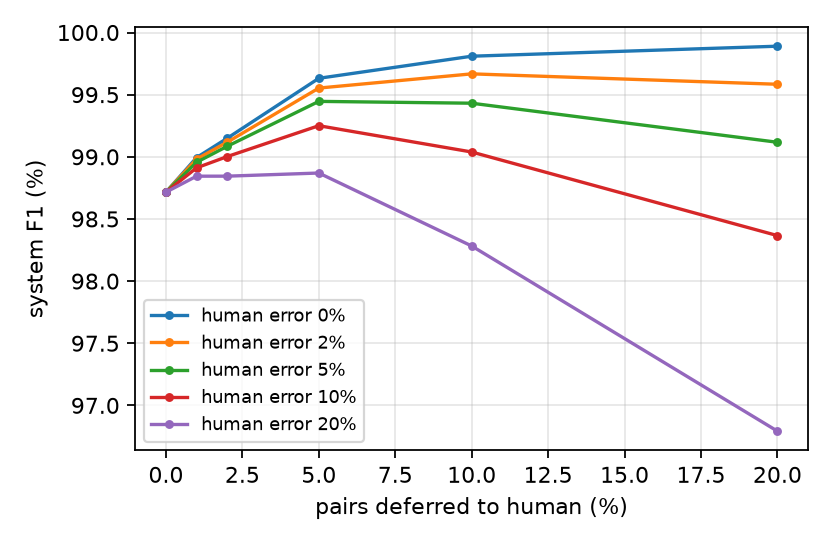

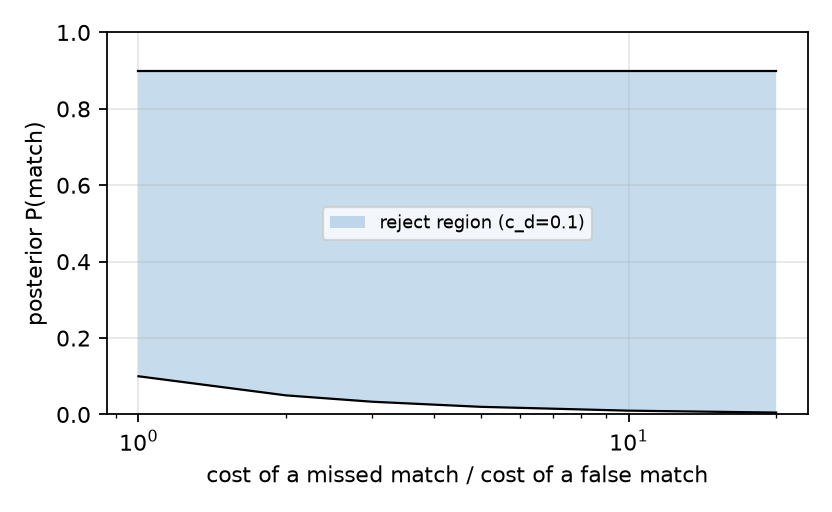

In [19]:
show("noisy_human.png",560);show("cost_region.png",560)

## 10. Scaling the expert: a 32B model with reasoning

Qwen3-32B-AWQ was run three ways (commands below, not re-run here; answers are loaded from `data/`): zero-shot one-word answers on the
same 30k pairs as the smaller models, a short chain of thought ("think step by step in at most five sentences, then answer") on the 10%
least confident test pairs, and native thinking mode (650 output tokens per pair) on the 5% least confident test pairs.

```bash
python er_llm32.py zs      # 1934 s
python er_llm32.py cot     # 205 s, 1845 pairs
python er_llm32.py think   # 450 s, 987 pairs
```

**The code that runs here.** The 32B expert in `er_llm32.py` and its evaluation in `er_llm32_eval.py`. The three modes differ in which pairs they score and how the model is sampled. The GPU run is `bash run32.sh` (32 + 4 + 8 minutes); the notebook loads its saved answers from `data/`.

`src/er_llm32.py`, lines 13 to 16 (model and the chain-of-thought instruction):

```python
MODEL=os.environ.get("ER_LLM32","Qwen/Qwen3-32B-AWQ");TAG=MODEL.split("/")[-1]
MODE=sys.argv[1] if len(sys.argv)>1 else "zs"
DATA=E.DATA
COT_SUFFIX="Think step by step in at most five short sentences, comparing names, dates, places and identifiers. Then give the final answer on its own last line as exactly 'Answer: yes' or 'Answer: no'."
```

`src/er_llm32.py`, lines 26 to 47 (answer parsing and the three modes):

```python
def parse_answer(text):
    t=text.lower()
    m=re.findall(r"answer\s*[:\-]?\s*\**\s*(yes|no)\b",t)
    if m:
        return 1 if m[-1]=="yes" else 0
    m=re.findall(r"\b(yes|no)\b",t)
    if m:
        return 1 if m[-1]=="yes" else 0
    return None

def main():
    from vllm import LLM,SamplingParams
    rows=E.load_rows();sp,te,order,wrong=subsets()
    if MODE=="zs":
        sel=list(sp["test"])+list(sp["train"][:12000]);think=False;suffix=None;maxtok=3;maxlen=6144
        s=SamplingParams(temperature=0,max_tokens=maxtok,logprobs=10)
    elif MODE=="cot":
        sel=sorted(set(order[:int(0.10*len(te))].tolist())|set(wrong.tolist()));think=False;suffix=COT_SUFFIX;maxlen=6144
        s=SamplingParams(temperature=0,max_tokens=600)
    elif MODE=="think":
        sel=sorted(set(order[:int(0.05*len(te))].tolist())|set(wrong.tolist()));think=True;suffix=None;maxlen=8192
        s=SamplingParams(temperature=0.6,top_p=0.95,top_k=20,max_tokens=6144,seed=0)
```

`src/er_llm32_eval.py`, lines 18 to 28 (the six expert files, confidence ranking, the hard core):

```python
experts={"Qwen2.5-7B zero-shot":load(f"{DATA}/llm_Qwen2.5-7B-Instruct_main.jsonl"),
         "Qwen2.5-14B zero-shot":load(f"{DATA}/llm_Qwen2.5-14B-Instruct-AWQ_main.jsonl"),
         "Qwen2.5-7B 4-shot":load(f"{DATA}/llm_Qwen2.5-7B-Instruct_4shot_main.jsonl"),
         "Qwen3-32B zero-shot":load(f"{DATA}/llm_Qwen3-32B-AWQ_main.jsonl"),
         "Qwen3-32B chain of thought":load(f"{DATA}/llm32_cot.jsonl"),
         "Qwen3-32B thinking":load(f"{DATA}/llm32_think.jsonl")}
conf=np.minimum(pm[te],1-pm[te]);order=te[np.argsort(-conf)]
yt=y[te];base_pred=ym[te];base_f1=f1_score(yt,base_pred);base_err=int((base_pred!=yt).sum())
res={"matcher_f1":float(base_f1),"matcher_errors":base_err,"experts":{}}
fracs=[0,0.01,0.02,0.03,0.05,0.075,0.1,0.15,0.2]
core=[i for i in te if ym[i]!=y[i] and all(i in experts[k] and experts[k][i]!=y[i] for k in ["Qwen2.5-7B zero-shot","Qwen2.5-14B zero-shot","Qwen2.5-7B 4-shot"])]
```

`src/er_llm32_eval.py`, lines 32 to 53 (per expert: alone, complementarity, deferral curve, the 5 percent breakdown, core recovery):

```python
for name,d in experts.items():
    e={}
    full=all(i in d for i in te)
    if full:
        pred=np.array([d[i] for i in te]);e["alone_f1"]=float(f1_score(yt,pred));e["alone_acc"]=float(accuracy_score(yt,pred))
        e["complementarity"]={"both_right":float(((base_pred==yt)&(pred==yt)).mean()),"matcher_only":float(((base_pred==yt)&(pred!=yt)).mean()),"llm_only":float(((base_pred!=yt)&(pred==yt)).mean()),"both_wrong":float(((base_pred!=yt)&(pred!=yt)).mean())}
    curve=[]
    for f in fracs:
        k=int(round(f*len(te)));dset=order[:k]
        if not all(i in d for i in dset):
            break
        yhat=ym.copy()
        for i in dset:
            yhat[i]=d[i]
        curve.append({"frac":f,"f1":float(f1_score(yt,yhat[te])),"errors":int((yhat[te]!=yt).sum())})
    e["curve"]=curve
    k=int(round(0.05*len(te)));dset=order[:k]
    if all(i in d for i in dset):
        mw=np.array([ym[i]!=y[i] for i in dset]);lp=np.array([d[i] for i in dset]);ly=np.array([y[i] for i in dset])
        e["deferred5"]={"n":int(k),"matcher_errors":int(mw.sum()),"fixed":int(((lp==ly)&mw).sum()),"broken":int(((lp!=ly)&(~mw)).sum()),"expert_error_rate":float((lp!=ly).mean())}
    cov=[i for i in core if i in d];e["core_answered"]=len(cov);e["core_fixed"]=int(sum(d[i]==y[i] for i in cov))
    wv=[i for i in wrong if i in d];e["matcher_wrong_answered"]=len(wv);e["matcher_wrong_fixed"]=int(sum(d[i]==y[i] for i in wv))
```

In [20]:
%run $SRC/er_llm32_eval.py

matcher test F1=98.72 errors=304 | hard core (wrong for matcher + 7B + 14B + 4shot) = 89
Qwen2.5-7B zero-shot         alone F1= 95.83 | 5% deferred: F1= 98.85 errors=271 fixed=145 broken=112 expert err on deferred=0.204 | core fixed 0/89 | matcher-wrong fixed 186/304
   curve: 0%:98.72 1%:98.76 2%:98.78 3%:98.80 5%:98.85 7.5%:98.73 10%:98.63 15%:98.28 20%:97.81
Qwen2.5-14B zero-shot        alone F1= 96.58 | 5% deferred: F1= 98.94 errors=250 fixed=147 broken=93 expert err on deferred=0.181 | core fixed 0/89 | matcher-wrong fixed 189/304
   curve: 0%:98.72 1%:98.77 2%:98.82 3%:98.87 5%:98.94 7.5%:98.87 10%:98.83 15%:98.52 20%:98.18
Qwen2.5-7B 4-shot            alone F1= 94.45 | 5% deferred: F1= 98.69 errors=308 fixed=146 broken=150 expert err on deferred=0.246 | core fixed 0/89 | matcher-wrong fixed 185/304
   curve: 0%:98.72 1%:98.77 2%:98.72 3%:98.68 5%:98.69 7.5%:98.51 10%:98.30 15%:97.72 20%:97.10
Qwen3-32B zero-shot          alone F1= 96.77 | 5% deferred: F1= 98.86 errors=270 fixed=

LLM32_EVAL_DONE


## 11. Paper figures

`collect_results.py` gathers the result files written by the runs above into `results_all.json`; `make_figs.py` regenerates every figure of the paper and slides from it.

wrote /eos/user/h/hchauhan/prml_proj/er/results_all.json sections: ['gate7', 'gate14', 'gatefs', 'matcher', 'extra', 'xtype', 'strata', 'core', 'leak', 'ablation', 'class_stats', 'llm_runs', 'fullpop', 'decision', 'llm32', 'data']


figs written: ['calibration.pdf', 'calibration.png', 'cost_region.pdf', 'cost_region.png', 'deferral_curves.pdf', 'deferral_curves.png', 'deferral_curves_Qwen2.5-14B-Instruct-AWQ.pdf', 'deferral_curves_Qwen2.5-14B-Instruct-AWQ.png', 'deferral_curves_Qwen2.5-7B-Instruct.pdf', 'deferral_curves_Qwen2.5-7B-Instruct.png', 'deferral_curves_Qwen2.5-7B-Instruct_4shot.pdf', 'deferral_curves_Qwen2.5-7B-Instruct_4shot.png', 'fig_complementarity.pdf', 'fig_complementarity.png', 'fig_core.pdf', 'fig_core.png', 'fig_cost.pdf', 'fig_cost.png', 'fig_deferral.pdf', 'fig_deferral.png', 'fig_deferral_human.pdf', 'fig_deferral_human.png', 'fig_deferral_zoom.pdf', 'fig_deferral_zoom.png', 'fig_experts.pdf', 'fig_experts.png', 'fig_importance.pdf', 'fig_importance.png', 'fig_learning_curve.pdf', 'fig_learning_curve.png', 'fig_matchers.pdf', 'fig_matchers.png', 'fig_noisy_human.pdf', 'fig_noisy_human.png', 'fig_pertype.pdf', 'fig_pertype.png', 'fig_strata.pdf', 'fig_strata.png', 'importance.pdf', 'importance

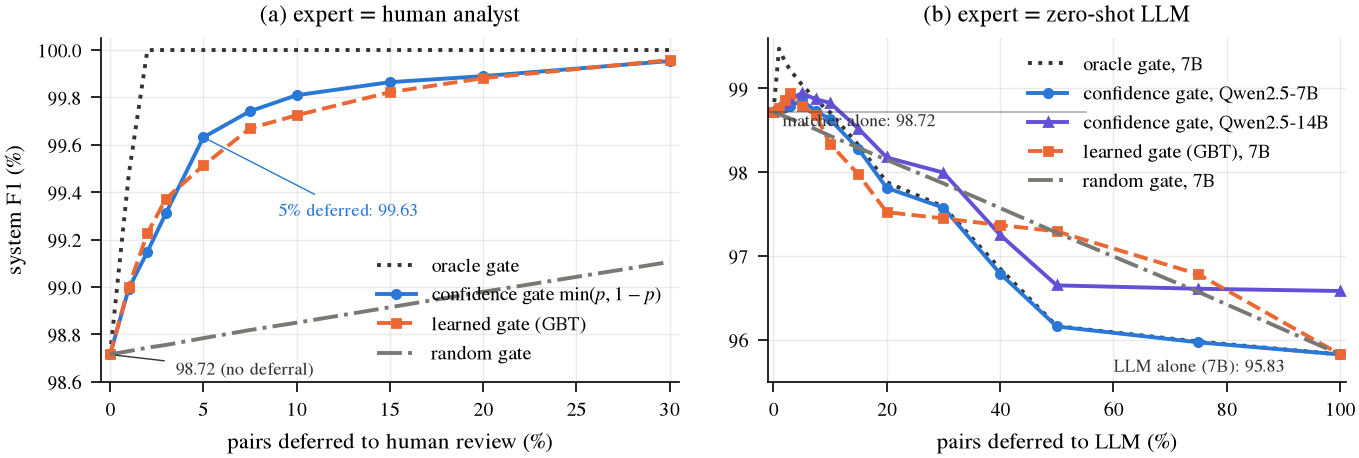

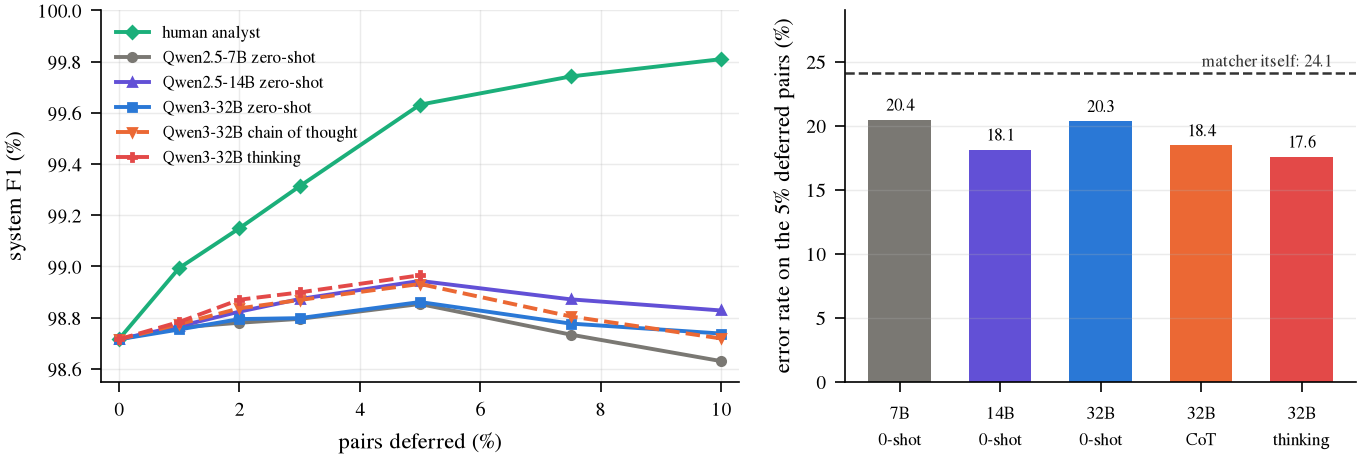

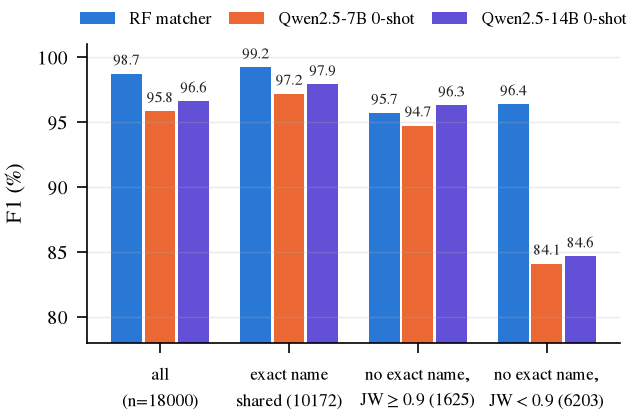

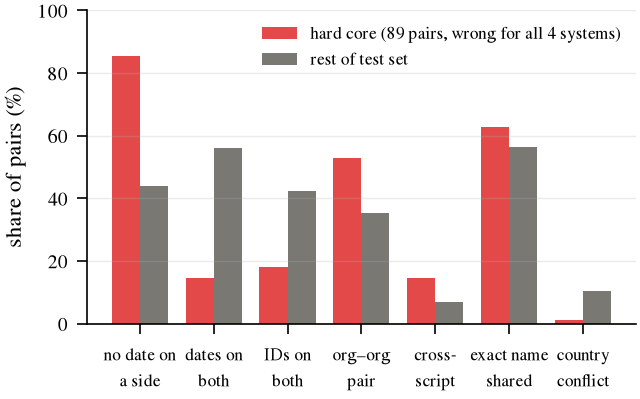

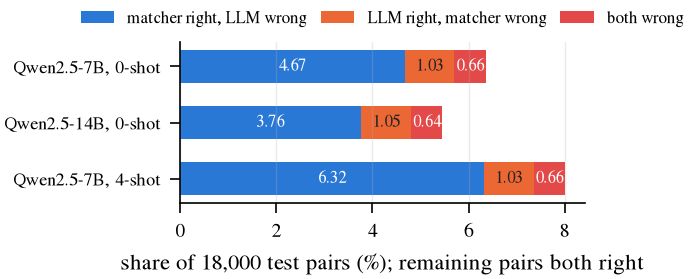

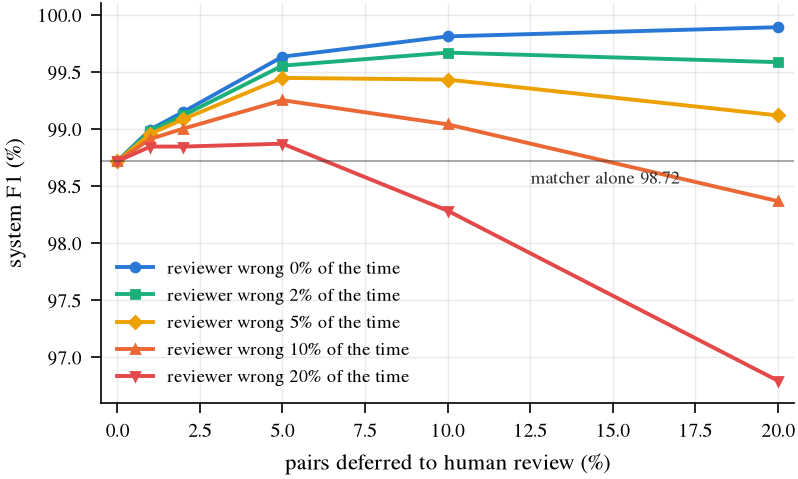

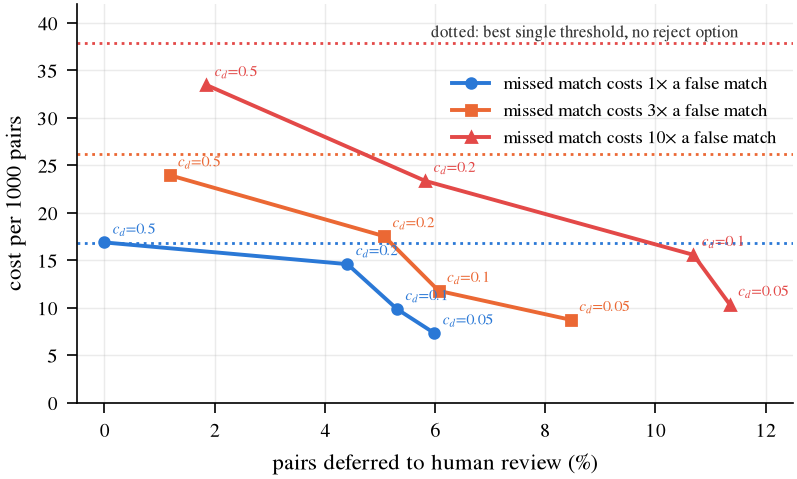

In [21]:
%run $SRC/collect_results.py
%run $SRC/make_figs.py
show("fig_deferral.png",900);show("fig_experts.png",900);show("fig_strata.png",620);show("fig_core.png",620);show("fig_complementarity.png",620);show("fig_noisy_human.png",520);show("fig_cost.png",520)

## 12. Headline numbers

* Random forest over 29 pair features: **98.7 F1** (AUC 0.997) on 18k test pairs; **98.5** on all 376k other pairs (95% CI 98.4 to 98.5);
  zero-shot Qwen2.5-7B 95.8, 14B 96.6, Qwen3-32B 96.8, best single-threshold rule 94.6, published production scorer 91.3. 100 labelled pairs beat the 7B LLM.
* Human review as expert, confidence gate: 5% of pairs reviewed removes 71% of errors (98.7 to 99.6 F1); learned gates do not beat it;
  a reviewer who is wrong 10% of the time still reaches 99.25, and the gate adapts to asymmetric costs (missed match 10x: 10.7% deferred, cost per 1000 pairs 37.9 to 15.6).
* LLM as expert: at most +0.25 F1 from 7B zero-shot to 32B with thinking, and the same +0.2 when combined with the matcher instead.
  On the deferred pairs every LLM is wrong 18 to 20% of the time against the matcher's own 24%, and the 89-pair hard core (same-name,
  attribute-poor pairs judged *different* by the analysts, 42% of them confidently wrong) stays hard: the thinking model recovers 9.
* Two dataset artefacts found and removed (relational stubs; cluster-size count features).

Live demo: `python demo.py pair --random`, `demo.py train`, `demo.py curve`, `demo.py core`, `demo.py ask --pid <id>` (see `DEMO.md`).